# Smartphone Price-Tier Classification from Hardware Specifications
## Random Forest vs Gradient Boosting on the Final Mobile Dataset (INR prices)
**Notebook type:** end-to-end Knowledge Discovery in Databases (KDD) workflow, Google Colab ready, all outputs included.

---
### 1. Introduction
The smartphone market spans phones from about Rs 7,700 to Rs 190,000. Price is driven by a mix of hardware (memory, storage, display, battery, cameras, processor) and brand positioning. This notebook asks whether a phone's **price tier** can be predicted from its specifications alone.

### 2. Research questions
* **RQ1.** Can hardware specs and brand discriminate **Budget**, **Mid-Range** and **Premium** phones?
* **RQ2.** Which specifications carry the most information about price tier?
* **RQ3.** How do **Random Forest** and **Gradient Boosting** compare in accuracy, class-wise errors, calibration and stability?
* **RQ4.** Where do the models fail, and are the errors "near misses" (adjacent tiers) or serious?

### 3. KDD methodology map
| KDD stage | What this notebook does |
|---|---|
| Selection | Load the CSV, document every column, define the 3-class target from `Price` |
| Preprocessing | Audit missing values and duplicates, repair encoding problems (RAM/ROM), harmonise brand names |
| Transformation | Engineer features, one-hot encode brand and processor, leakage-safe imputation inside a Pipeline |
| Data mining | Tune and train **two** classifiers: Random Forest and Gradient Boosting |
| Evaluation | Test-set metrics, ROC/PR/calibration, learning curves, permutation importance, partial dependence, repeated CV, statistical comparison, error analysis |

### 4. Scope and honesty notes
* The target is a **relative** tier (equal-sized thirds of this dataset), not an absolute market definition.
* `Price` is **never** used as a feature. Only specs and brand are.
* This is a research/learning pipeline, not a pricing tool.

## Part A. Setup

In [1]:
import os, re, random, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

import sklearn
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import label_binarize, StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     GridSearchCV, cross_val_score, cross_val_predict, learning_curve)
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve, auc,
                             precision_recall_curve, average_precision_score, matthews_corrcoef,
                             cohen_kappa_score, mean_absolute_error)

warnings.filterwarnings("ignore")
RANDOM_SEED = 42
random.seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)

print("Python libraries loaded successfully")
print("  NumPy        :", np.__version__)
print("  Pandas       :", pd.__version__)
print("  SciPy        :", __import__("scipy").__version__)
print("  Scikit-learn :", sklearn.__version__)
print("  Seaborn      :", sns.__version__)

Python libraries loaded successfully
  NumPy        : 2.4.4
  Pandas       : 3.0.2
  SciPy        : 1.17.1
  Scikit-learn : 1.8.0
  Seaborn      : 0.13.2


In [2]:
# Output folders, plotting style, colours and a helper that saves + shows each figure
OUT_DIR = Path("/content/outputs") if Path("/content").exists() else Path("outputs")
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 300, "savefig.bbox": "tight",
                     "axes.titlesize": 12, "axes.labelsize": 10.5, "legend.fontsize": 9.5,
                     "grid.alpha": 0.35, "grid.linestyle": "--"})

TIER_ORDER  = ["Budget", "Mid-Range", "Premium"]
TIER_COLORS = {"Budget": "#2b8cbe", "Mid-Range": "#f39c12", "Premium": "#c0392b"}
MODEL_COLORS = {"Random Forest": "#2b5c8f", "Gradient Boosting": "#d62728"}
FIG_COUNTER = {"n": 0}

def save_show(name, tight=True):
    """Save the current figure to FIG_DIR and display it inline."""
    FIG_COUNTER["n"] += 1
    if tight:
        plt.tight_layout()
    plt.savefig(FIG_DIR / name)
    plt.show()

print("Output directory :", OUT_DIR.resolve())
print("Figures directory:", FIG_DIR.resolve())

Output directory : /content/outputs
Figures directory: /content/outputs/figures


## Part B. Data Selection and Loading

In [3]:
CSV_NAME = "final_mobile_dataset.csv"

def locate_csv():
    for p in [Path(CSV_NAME), Path("/content") / CSV_NAME, Path("/content/drive/MyDrive") / CSV_NAME]:
        if p.exists():
            return p
    from google.colab import files          # opens the upload dialog in Colab
    print("Please upload", CSV_NAME)
    uploaded = files.upload()
    return Path(list(uploaded.keys())[0])

csv_path = locate_csv()
df_raw = pd.read_csv(csv_path)
print(f"Loaded : {csv_path}")
print(f"Shape  : {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
display(df_raw.head(8))

Loaded : final_mobile_dataset.csv
Shape  : 1,056 rows x 14 columns


,Processor,Brand,Ram_GB,Rom_GB,Battery_Capacity,Display_Size(Inches),Display_Quality,Refresh_Rate,Rear_Camera_MP,Front_Camera_MP,Android,IOS,Version,Price
0,MediaTek,OnePlus,8,128,7100,6.77,AMOLED,120,50.0,16.0,1,0,15,22999
1,Snapdragon,vivo,8,128,6000,6.77,AMOLED,120,50.0,50.0,1,0,15,34999
2,MediaTek,realme,8,256,7000,6.78,AMOLED,120,50.0,32.0,1,0,15,39998
3,MediaTek,POCO,8,256,6550,6.67,AMOLED,120,50.0,20.0,1,0,15,23998
4,Samsung,Samsung,8,128,5000,6.70,AMOLED,120,50.0,12.0,1,0,15,38999
5,Samsung,Samsung,8,128,5000,6.60,AMOLED,120,50.0,13.0,1,0,14,20290
6,MediaTek,OPPO,1,256,6200,6.83,LCD,120,50.0,50.0,1,0,15,49999
7,Snapdragon,Samsung,1,256,5000,6.90,AMOLED,120,50.0,12.0,1,0,15,117999


In [4]:
# Data dictionary: what each column means and how it is used
data_dictionary = pd.DataFrame([
    ("Processor",            "categorical", "Chip family (MediaTek, Snapdragon, Samsung, Apple, Google)", "Feature (one-hot)"),
    ("Brand",                "categorical", "Manufacturer name (contains naming variants)",              "Feature (cleaned, one-hot)"),
    ("Ram_GB",               "numeric",     "RAM in GB (contains encoding problems, see Part C)",        "Feature (repaired)"),
    ("Rom_GB",               "numeric",     "Internal storage in GB (1 means 1 TB)",                     "Feature (repaired)"),
    ("Battery_Capacity",     "numeric",     "Battery size in mAh",                                       "Feature"),
    ("Display_Size(Inches)", "numeric",     "Screen diagonal in inches",                                 "Feature"),
    ("Display_Quality",      "categorical", "Panel type: AMOLED or LCD",                                 "Feature (binary)"),
    ("Refresh_Rate",         "numeric",     "Screen refresh rate in Hz",                                 "Feature"),
    ("Rear_Camera_MP",       "numeric",     "Main rear camera resolution (MP)",                          "Feature"),
    ("Front_Camera_MP",      "numeric",     "Selfie camera resolution (MP)",                             "Feature"),
    ("Android",              "binary",      "1 if Android",                                              "Dropped (redundant with IOS)"),
    ("IOS",                  "binary",      "1 if iOS",                                                  "Feature"),
    ("Version",              "numeric",     "Operating-system major version",                            "Feature"),
    ("Price",                "numeric",     "Launch price in INR",                                       "TARGET source (never a feature)"),
], columns=["column", "type", "meaning", "role in this notebook"])
display(data_dictionary)

,column,type,meaning,role in this notebook
0,Processor,categorical,"Chip family (MediaTek, Snapdragon, Samsung, Ap...",Feature (one-hot)
1,Brand,categorical,Manufacturer name (contains naming variants),"Feature (cleaned, one-hot)"
2,Ram_GB,numeric,"RAM in GB (contains encoding problems, see Par...",Feature (repaired)
3,Rom_GB,numeric,Internal storage in GB (1 means 1 TB),Feature (repaired)
4,Battery_Capacity,numeric,Battery size in mAh,Feature
5,Display_Size(Inches),numeric,Screen diagonal in inches,Feature
6,Display_Quality,categorical,Panel type: AMOLED or LCD,Feature (binary)
7,Refresh_Rate,numeric,Screen refresh rate in Hz,Feature
8,Rear_Camera_MP,numeric,Main rear camera resolution (MP),Feature
9,Front_Camera_MP,numeric,Selfie camera resolution (MP),Feature


## Part C. Data Quality Audit and Preprocessing

In [5]:
audit = pd.DataFrame({"dtype": df_raw.dtypes.astype(str),
                      "missing": df_raw.isna().sum(),
                      "missing_%": (df_raw.isna().mean() * 100).round(2),
                      "n_unique": df_raw.nunique()})
display(audit)
print(f"Exact duplicate rows : {df_raw.duplicated().sum()} (rows involved in a duplicate group: {df_raw.duplicated(keep=False).sum()})")
print(f"Total missing cells  : {int(df_raw.isna().sum().sum())}")
print("\nDescriptive statistics (numeric columns):")
display(df_raw.describe().T.round(2))

,dtype,missing,missing_%,n_unique
Processor,str,0,0.00,5
Brand,str,0,0.00,30
Ram_GB,int64,0,0.00,6
Rom_GB,int64,0,0.00,6
Battery_Capacity,int64,0,0.00,99
Display_Size(Inches),float64,0,0.00,43
Display_Quality,str,0,0.00,2
Refresh_Rate,int64,0,0.00,5
Rear_Camera_MP,float64,9,0.85,14
Front_Camera_MP,float64,9,0.85,20


Exact duplicate rows : 7 (rows involved in a duplicate group: 13)
Total missing cells  : 18

Descriptive statistics (numeric columns):


,count,mean,std,min,25%,50%,75%,max
Ram_GB,1056.0,5.48,2.89,1.0,1.00,6.0,8.00,8.00
Rom_GB,1056.0,208.14,120.25,1.0,128.00,128.0,256.00,512.00
Battery_Capacity,1056.0,5017.05,734.15,1060.0,4700.00,5000.0,5160.00,9600.00
Display_Size(Inches),1056.0,6.65,0.25,4.7,6.59,6.7,6.77,8.03
Refresh_Rate,1056.0,113.79,18.31,60.0,120.00,120.0,120.00,165.00
Rear_Camera_MP,1047.0,55.16,30.22,2.0,50.00,50.0,50.00,200.00
Front_Camera_MP,1047.0,20.08,12.74,2.0,12.00,16.0,32.00,60.00
Android,1056.0,0.94,0.24,0.0,1.00,1.0,1.00,1.00
IOS,1056.0,0.06,0.24,0.0,0.00,0.0,0.00,1.00
Version,1056.0,13.43,1.56,9.0,12.00,14.0,14.00,18.00


In [6]:
# Brand naming problems, RAM and ROM value counts
print("Distinct brand labels :", df_raw["Brand"].nunique())
print(sorted(df_raw["Brand"].unique()))
print("\nRam_GB raw value counts :", df_raw["Ram_GB"].value_counts().sort_index().to_dict())
print("Rom_GB raw value counts :", df_raw["Rom_GB"].value_counts().sort_index().to_dict())

print("\nMedian price (INR) by raw RAM value:")
display(df_raw.groupby("Ram_GB")["Price"].agg(["count", "median", "min", "max"]).round(0))

Distinct brand labels : 30
['AGM', 'Acer', 'Acera', 'Alcatel', 'Apple', 'Asus', 'Blackview', 'CMF', 'Galaxy', 'Google', 'HMD', 'Honor', 'Infinix', 'Itel', 'LG', 'Lava', 'Moto', 'Motorola', 'Nokia', 'Nothing', 'OPPO', 'OnePlus', 'POCO', 'Samsung', 'Tecno', 'Ulefone', 'Xiaomi', 'iQOO', 'realme', 'vivo']

Ram_GB raw value counts : {1: 266, 2: 2, 4: 109, 5: 1, 6: 176, 8: 502}
Rom_GB raw value counts : {1: 15, 8: 1, 64: 38, 128: 514, 256: 384, 512: 104}

Median price (INR) by raw RAM value:


,count,median,min,max
Ram_GB,,,,
1,266,39999.0,15455,189999
2,2,104998.0,89997,119999
4,109,11999.0,7689,94900
5,1,15999.0,15999,15999
6,176,15999.0,8909,184900
8,502,22999.0,9699,161900


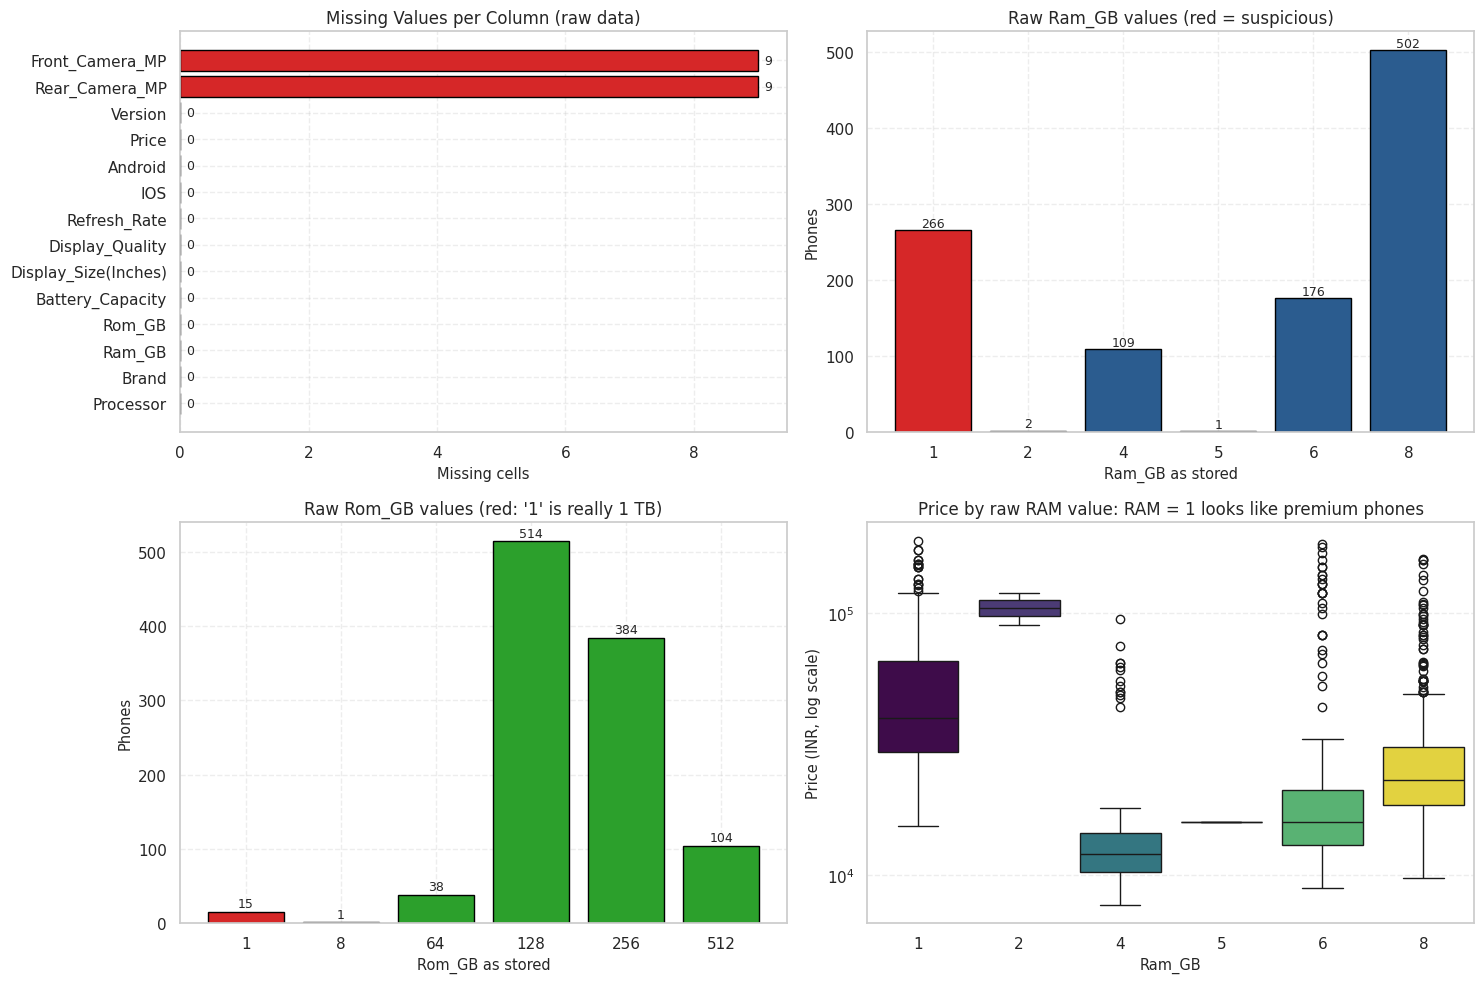

In [7]:
# FIGURE 1: Data-quality overview
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

miss = df_raw.isna().sum().sort_values()
axes[0, 0].barh(miss.index, miss.values, color=np.where(miss.values > 0, "#d62728", "#9ecae1"), edgecolor="black")
for i, v in enumerate(miss.values):
    axes[0, 0].text(v + 0.1, i, str(int(v)), va="center", fontsize=9)
axes[0, 0].set_title("Missing Values per Column (raw data)"); axes[0, 0].set_xlabel("Missing cells")

rc = df_raw["Ram_GB"].value_counts().sort_index()
axes[0, 1].bar(rc.index.astype(str), rc.values, color=["#d62728" if i in (1, 2) else "#2b5c8f" for i in rc.index], edgecolor="black")
for i, v in enumerate(rc.values):
    axes[0, 1].text(i, v + 4, str(v), ha="center", fontsize=9)
axes[0, 1].set_title("Raw Ram_GB values (red = suspicious)"); axes[0, 1].set_xlabel("Ram_GB as stored"); axes[0, 1].set_ylabel("Phones")

oc = df_raw["Rom_GB"].value_counts().sort_index()
axes[1, 0].bar(oc.index.astype(str), oc.values, color=["#d62728" if i == 1 else "#2ca02c" for i in oc.index], edgecolor="black")
for i, v in enumerate(oc.values):
    axes[1, 0].text(i, v + 6, str(v), ha="center", fontsize=9)
axes[1, 0].set_title("Raw Rom_GB values (red: '1' is really 1 TB)"); axes[1, 0].set_xlabel("Rom_GB as stored"); axes[1, 0].set_ylabel("Phones")

sns.boxplot(data=df_raw, x="Ram_GB", y="Price", hue="Ram_GB", palette="viridis", legend=False, ax=axes[1, 1])
axes[1, 1].set_yscale("log"); axes[1, 1].set_title("Price by raw RAM value: RAM = 1 looks like premium phones")
axes[1, 1].set_ylabel("Price (INR, log scale)")
save_show("fig01_data_quality_overview.png")

**Interpretation of Figure 1 (data quality).**

* **Missing values are minimal:** only `Rear_Camera_MP` and `Front_Camera_MP` have gaps (9 phones each, 0.85%). They will be imputed inside the Pipeline using training data only.
* **RAM has an encoding problem.** 266 phones store `Ram_GB = 1`, which is implausible for phones that also carry 256 to 1024 GB of storage. The bottom-right box plot confirms it: their median price (Rs 39,999) is far above the 4 GB group (Rs 11,999) and even above the 8 GB group (Rs 22,999). Two more phones store RAM = 2 at Rs 90,000 to 120,000. The most likely cause is a truncated '12' or '16' (first digit kept).
* **ROM has a unit problem.** 15 phones store `Rom_GB = 1`, which is 1 TB, not 1 GB.

Both are repaired in the next cells, and Part L tests how much the RAM assumption matters.

In [8]:
# CLEANING STEP 1: harmonise brand names, drop exact duplicates, repair ROM and RAM
BRAND_MAP = {"Moto": "Motorola", "Galaxy": "Samsung", "Acera": "Acer",
             "OPPO": "Oppo", "vivo": "Vivo", "realme": "Realme"}

df = df_raw.drop_duplicates().reset_index(drop=True).copy()
df["brand"] = df["Brand"].str.strip().replace(BRAND_MAP)

# ROM: a stored value of 1 means 1 TB
df["rom_gb"] = df["Rom_GB"].replace({1: 1024}).astype(float)

# RAM: values 1 and 2 are not credible next to 256-1024 GB storage and 40k-190k INR prices.
# Most likely a truncated "12"/"16" (first digit kept). We recode them to 12 GB, keep a flag,
# and test this assumption against alternatives in the sensitivity analysis later.
df["ram_recoded"] = df["Ram_GB"].isin([1, 2]).astype(int)
df["ram_gb"] = df["Ram_GB"].where(~df["Ram_GB"].isin([1, 2]), 12).astype(float)

print(f"Rows: {len(df_raw):,} -> {len(df):,} after removing {len(df_raw) - len(df)} exact duplicates")
print(f"Brand labels: {df_raw['Brand'].nunique()} -> {df['brand'].nunique()} after harmonisation")
print(f"Phones with ROM stored as '1' recoded to 1024 GB: {int((df_raw.drop_duplicates()['Rom_GB'] == 1).sum())}")
print(f"Phones with RAM in {{1, 2}} recoded to 12 GB     : {int(df['ram_recoded'].sum())}")
print("\nBrand counts after cleaning:")
print(df["brand"].value_counts().to_dict())

Rows: 1,056 -> 1,049 after removing 7 exact duplicates
Brand labels: 30 -> 27 after harmonisation
Phones with ROM stored as '1' recoded to 1024 GB: 15
Phones with RAM in {1, 2} recoded to 12 GB     : 267

Brand counts after cleaning:
{'Samsung': 163, 'Realme': 155, 'Vivo': 120, 'Xiaomi': 78, 'OnePlus': 68, 'iQOO': 68, 'Oppo': 66, 'Apple': 62, 'POCO': 51, 'Motorola': 51, 'Tecno': 32, 'Infinix': 31, 'Lava': 21, 'Nothing': 18, 'Google': 16, 'Asus': 11, 'Honor': 7, 'Acer': 5, 'Itel': 5, 'Alcatel': 5, 'CMF': 4, 'Ulefone': 4, 'Nokia': 3, 'HMD': 2, 'LG': 1, 'AGM': 1, 'Blackview': 1}


In [9]:
# CLEANING STEP 2: rename columns, binary encodings, rare-brand grouping
df = df.rename(columns={"Battery_Capacity": "battery_mah", "Display_Size(Inches)": "display_in",
                        "Refresh_Rate": "refresh_hz", "Rear_Camera_MP": "rear_mp",
                        "Front_Camera_MP": "front_mp", "Version": "os_version",
                        "Price": "price_inr", "Processor": "processor"})
df["is_ios"]    = df["IOS"].astype(int)
df["is_amoled"] = (df["Display_Quality"] == "AMOLED").astype(int)
assert ((df["Android"] + df["IOS"]) == 1).all(), "Android and IOS should be mutually exclusive"
print("Android and IOS are exact complements, so Android is dropped as redundant.")

# Brands with fewer than 15 phones are pooled into 'Other' (reduces sparse one-hot columns)
brand_counts = df["brand"].value_counts()
MIN_BRAND = 15
df["brand_group"] = df["brand"].where(df["brand"].map(brand_counts) >= MIN_BRAND, "Other")
print(f"\nBrands kept individually (>= {MIN_BRAND} phones): {sorted(df['brand_group'].unique())}")
print(df["brand_group"].value_counts().to_dict())
print("\nRemaining missing values:")
print(df[["rear_mp", "front_mp"]].isna().sum().to_string())
print("(These 9 missing camera values are imputed inside the modeling Pipeline, using training data only.)")

Android and IOS are exact complements, so Android is dropped as redundant.

Brands kept individually (>= 15 phones): ['Apple', 'Google', 'Infinix', 'Lava', 'Motorola', 'Nothing', 'OnePlus', 'Oppo', 'Other', 'POCO', 'Realme', 'Samsung', 'Tecno', 'Vivo', 'Xiaomi', 'iQOO']
{'Samsung': 163, 'Realme': 155, 'Vivo': 120, 'Xiaomi': 78, 'OnePlus': 68, 'iQOO': 68, 'Oppo': 66, 'Apple': 62, 'POCO': 51, 'Motorola': 51, 'Other': 49, 'Tecno': 32, 'Infinix': 31, 'Lava': 21, 'Nothing': 18, 'Google': 16}

Remaining missing values:
rear_mp     9
front_mp    9
(These 9 missing camera values are imputed inside the modeling Pipeline, using training data only.)


## Part D. Target Formulation and Feature Engineering

In [10]:
# TARGET: three equal-sized price tiers (tertiles of INR price)
q1, q2 = df["price_inr"].quantile([1/3, 2/3])
df["price_tier"] = pd.cut(df["price_inr"], bins=[-np.inf, q1, q2, np.inf], labels=TIER_ORDER)

print(f"Tier thresholds (INR): Budget <= {q1:,.0f} < Mid-Range <= {q2:,.0f} < Premium")
tier_summary = df.groupby("price_tier", observed=True)["price_inr"].agg(["count", "min", "median", "max"]).round(0)
tier_summary["share_%"] = (tier_summary["count"] / len(df) * 100).round(1)
display(tier_summary)

Tier thresholds (INR): Budget <= 18,990 < Mid-Range <= 30,999 < Premium


,count,min,median,max,share_%
price_tier,,,,,
Budget,352,7689,14340.0,18990,33.6
Mid-Range,348,18998,23772.0,30999,33.2
Premium,349,31500,51799.0,189999,33.3


In [11]:
# FEATURE MATRIX: numeric specs + engineered ratios + one-hot brand/processor
def build_feature_matrix(d, ram):
    num = pd.DataFrame({
        "ram_gb": ram, "rom_gb": d["rom_gb"], "battery_mah": d["battery_mah"], "display_in": d["display_in"],
        "refresh_hz": d["refresh_hz"], "rear_mp": d["rear_mp"], "front_mp": d["front_mp"],
        "os_version": d["os_version"], "is_ios": d["is_ios"], "is_amoled": d["is_amoled"]})
    # engineered features
    num["camera_sum_mp"]    = num["rear_mp"] + num["front_mp"]
    num["battery_per_inch"] = num["battery_mah"] / num["display_in"]
    num["rom_per_ram"]      = num["rom_gb"] / num["ram_gb"]
    cats = pd.concat([pd.get_dummies(d["brand_group"], prefix="brand"),
                      pd.get_dummies(d["processor"], prefix="cpu")], axis=1)
    return pd.concat([num, cats], axis=1).astype(float)

X = build_feature_matrix(df, df["ram_gb"])
y = df["price_tier"].map({t: i for i, t in enumerate(TIER_ORDER)}).astype(int)
NUM_COLS = [c for c in X.columns if not c.startswith(("brand_", "cpu_"))]

print(f"Feature matrix: {X.shape[0]:,} rows x {X.shape[1]} features")
print(f"  numeric/engineered : {len(NUM_COLS)}  -> {NUM_COLS}")
print(f"  one-hot columns    : {X.shape[1] - len(NUM_COLS)}")
print("\nPrice is NOT in X (target leakage check):", not any("price" in c for c in X.columns))

Feature matrix: 1,049 rows x 34 features
  numeric/engineered : 13  -> ['ram_gb', 'rom_gb', 'battery_mah', 'display_in', 'refresh_hz', 'rear_mp', 'front_mp', 'os_version', 'is_ios', 'is_amoled', 'camera_sum_mp', 'battery_per_inch', 'rom_per_ram']
  one-hot columns    : 21

Price is NOT in X (target leakage check): True


In [12]:
# STRATIFIED TRAIN / TEST SPLIT (80 / 20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_SEED)

split_table = pd.DataFrame({
    "train": y_train.map(dict(enumerate(TIER_ORDER))).value_counts().reindex(TIER_ORDER),
    "test":  y_test.map(dict(enumerate(TIER_ORDER))).value_counts().reindex(TIER_ORDER)})
split_table.loc["TOTAL"] = split_table.sum()
display(split_table)
print(f"Train: {len(X_train):,} phones | Test: {len(X_test):,} phones | classes stratified in both")

,train,test
price_tier,,
Budget,282,70
Mid-Range,278,70
Premium,279,70
TOTAL,839,210


Train: 839 phones | Test: 210 phones | classes stratified in both


## Part E. Exploratory Data Analysis

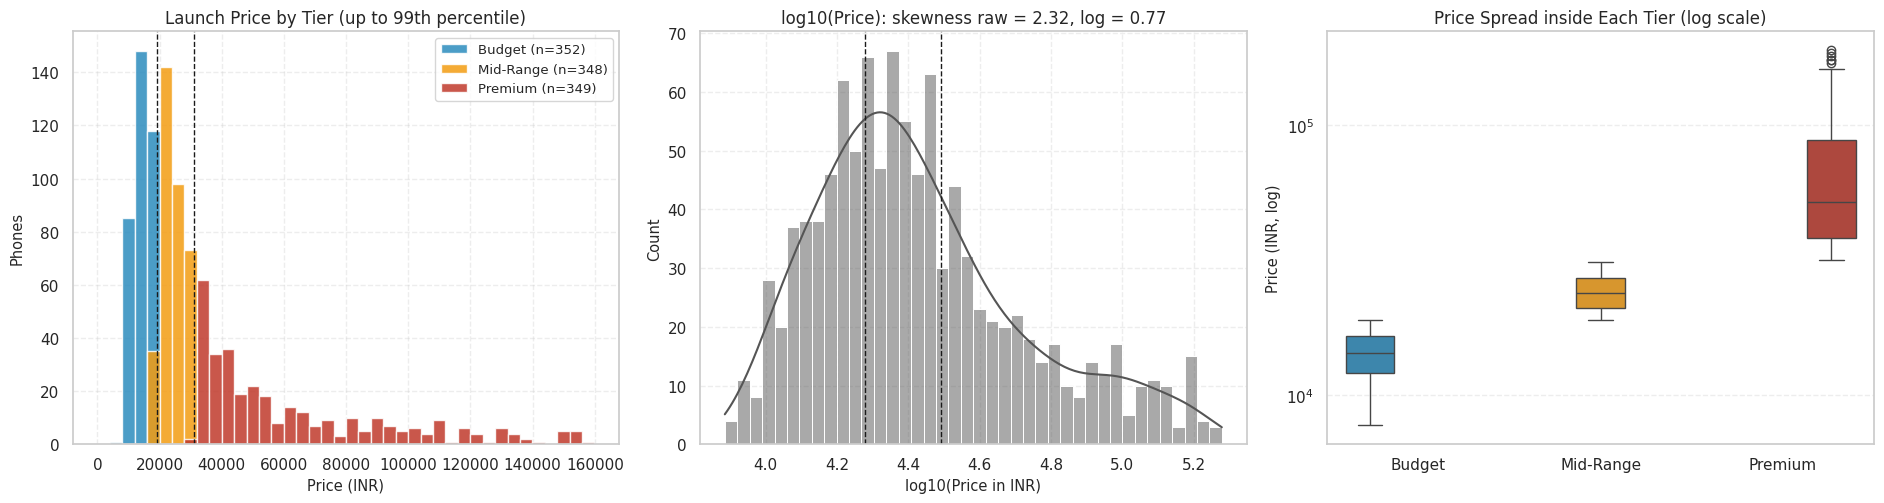

In [13]:
# FIGURE 2: Price distribution (raw, log, per tier)
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
cap = df["price_inr"].quantile(0.99)
bins = np.linspace(0, cap, 41)
for t in TIER_ORDER:
    axes[0].hist(df.loc[(df["price_tier"] == t) & (df["price_inr"] <= cap), "price_inr"], bins=bins,
                 color=TIER_COLORS[t], alpha=0.85, edgecolor="white", label=f"{t} (n={int((df['price_tier']==t).sum())})")
axes[0].axvline(q1, color="k", ls="--", lw=1); axes[0].axvline(q2, color="k", ls="--", lw=1)
axes[0].set_title("Launch Price by Tier (up to 99th percentile)"); axes[0].set_xlabel("Price (INR)"); axes[0].set_ylabel("Phones"); axes[0].legend()

logp = np.log10(df["price_inr"])
sns.histplot(logp, bins=40, kde=True, color="#555555", ax=axes[1])
axes[1].axvline(np.log10(q1), color="k", ls="--", lw=1); axes[1].axvline(np.log10(q2), color="k", ls="--", lw=1)
axes[1].set_title(f"log10(Price): skewness raw = {stats.skew(df['price_inr']):.2f}, log = {stats.skew(logp):.2f}")
axes[1].set_xlabel("log10(Price in INR)")

sns.boxplot(data=df, x="price_tier", y="price_inr", order=TIER_ORDER, hue="price_tier", palette=TIER_COLORS, legend=False, ax=axes[2])
axes[2].set_yscale("log"); axes[2].set_title("Price Spread inside Each Tier (log scale)"); axes[2].set_xlabel(""); axes[2].set_ylabel("Price (INR, log)")
save_show("fig02_price_distribution.png")

**Interpretation of Figure 2 (price distribution).**

* Prices run from Rs 7,689 to Rs 189,999. The mean (Rs 34,997) is well above the median (Rs 23,747), a classic **right-skewed** price distribution; the log scale in the middle panel makes it far more symmetric.
* The tertile cut-offs are **Rs 18,990** and **Rs 30,999**, giving three nearly equal classes (352 / 348 / 349 phones, 33.6% / 33.2% / 33.3%). Class imbalance is therefore not a concern here.
* The Premium tier is by far the widest (Rs 31,500 to Rs 189,999), while Budget spans only Rs 7,689 to Rs 18,990. Premium contains very different phones (a Rs 35k mid-premium Android and a Rs 190k flagship share a label), which makes the tier internally heterogeneous.

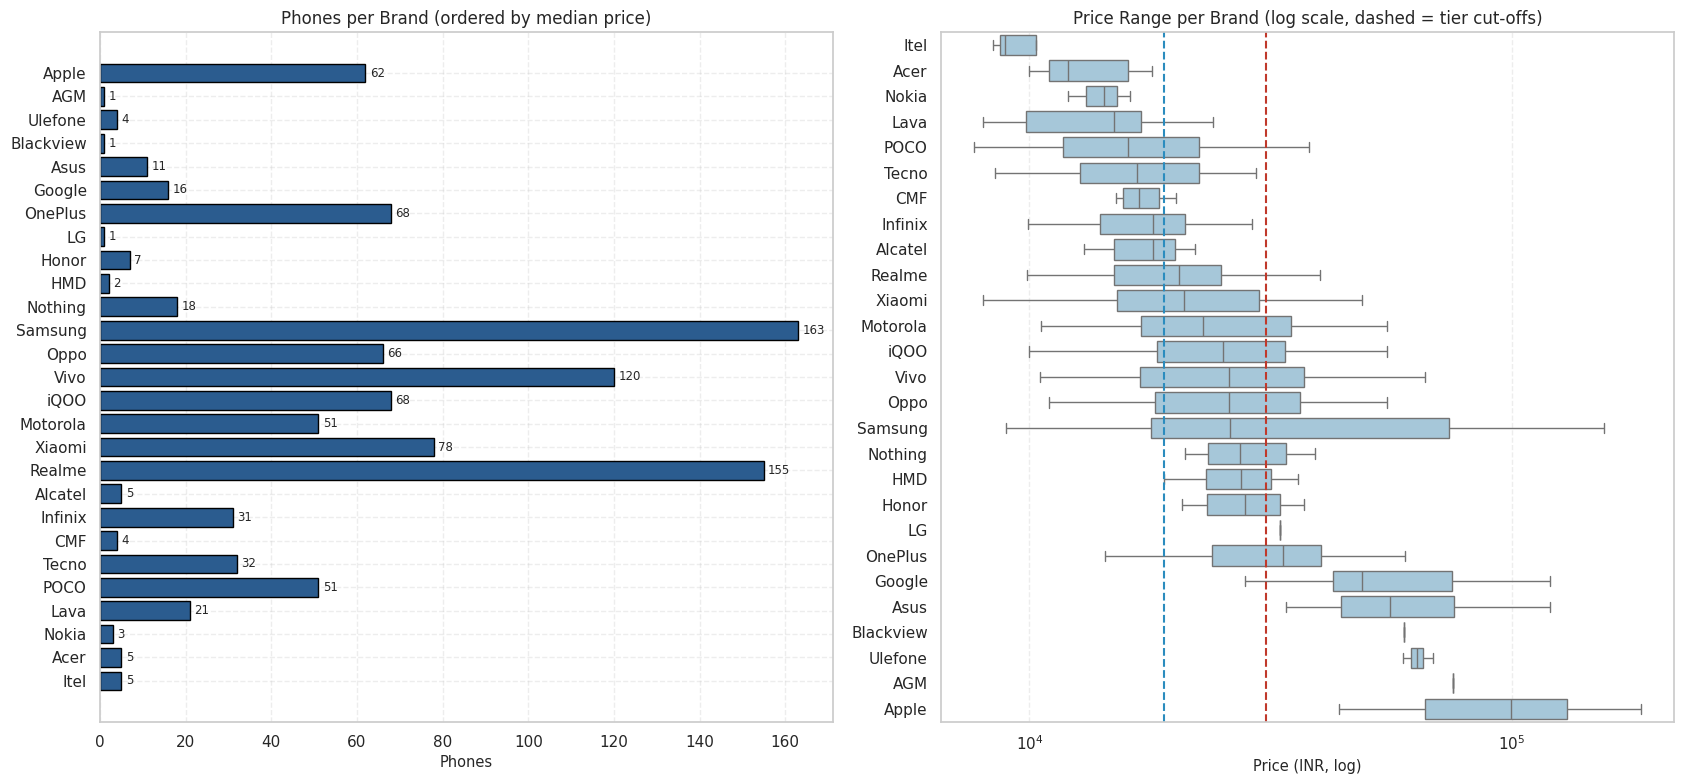

In [14]:
# FIGURE 3: Brand positioning (count and price)
order = df.groupby("brand")["price_inr"].median().sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(17, 8))

cnt = df["brand"].value_counts().reindex(order)
axes[0].barh(cnt.index, cnt.values, color="#2b5c8f", edgecolor="black")
for i, v in enumerate(cnt.values):
    axes[0].text(v + 1, i, str(v), va="center", fontsize=8.5)
axes[0].set_title("Phones per Brand (ordered by median price)"); axes[0].set_xlabel("Phones")

sns.boxplot(data=df, y="brand", x="price_inr", order=order, color="#9ecae1", showfliers=False, ax=axes[1])
axes[1].set_xscale("log"); axes[1].axvline(q1, color="#2b8cbe", ls="--"); axes[1].axvline(q2, color="#c0392b", ls="--")
axes[1].set_title("Price Range per Brand (log scale, dashed = tier cut-offs)"); axes[1].set_xlabel("Price (INR, log)"); axes[1].set_ylabel("")
save_show("fig03_brand_positioning.png")

**Interpretation of Figure 3 (brand positioning).**

* Median prices climb from **Lava (Rs 14,999)** and **POCO (Rs 15,990)** through Realme (Rs 20,390), Samsung (Rs 25,999) and OnePlus (Rs 33,495) up to **Google (Rs 48,999)** and **Apple (Rs 99,700)**.
* The box plots overlap heavily for mainstream brands. Samsung is split almost evenly across tiers (48 Budget, 48 Mid-Range, 67 Premium) and Realme spans all three (70 / 69 / 16). **Brand alone cannot decide the tier**; specs must do the work.
* Apple is the exception: all 62 Apple phones are Premium, and Tecno and Infinix are mostly Budget. These brands will be easy for the models.

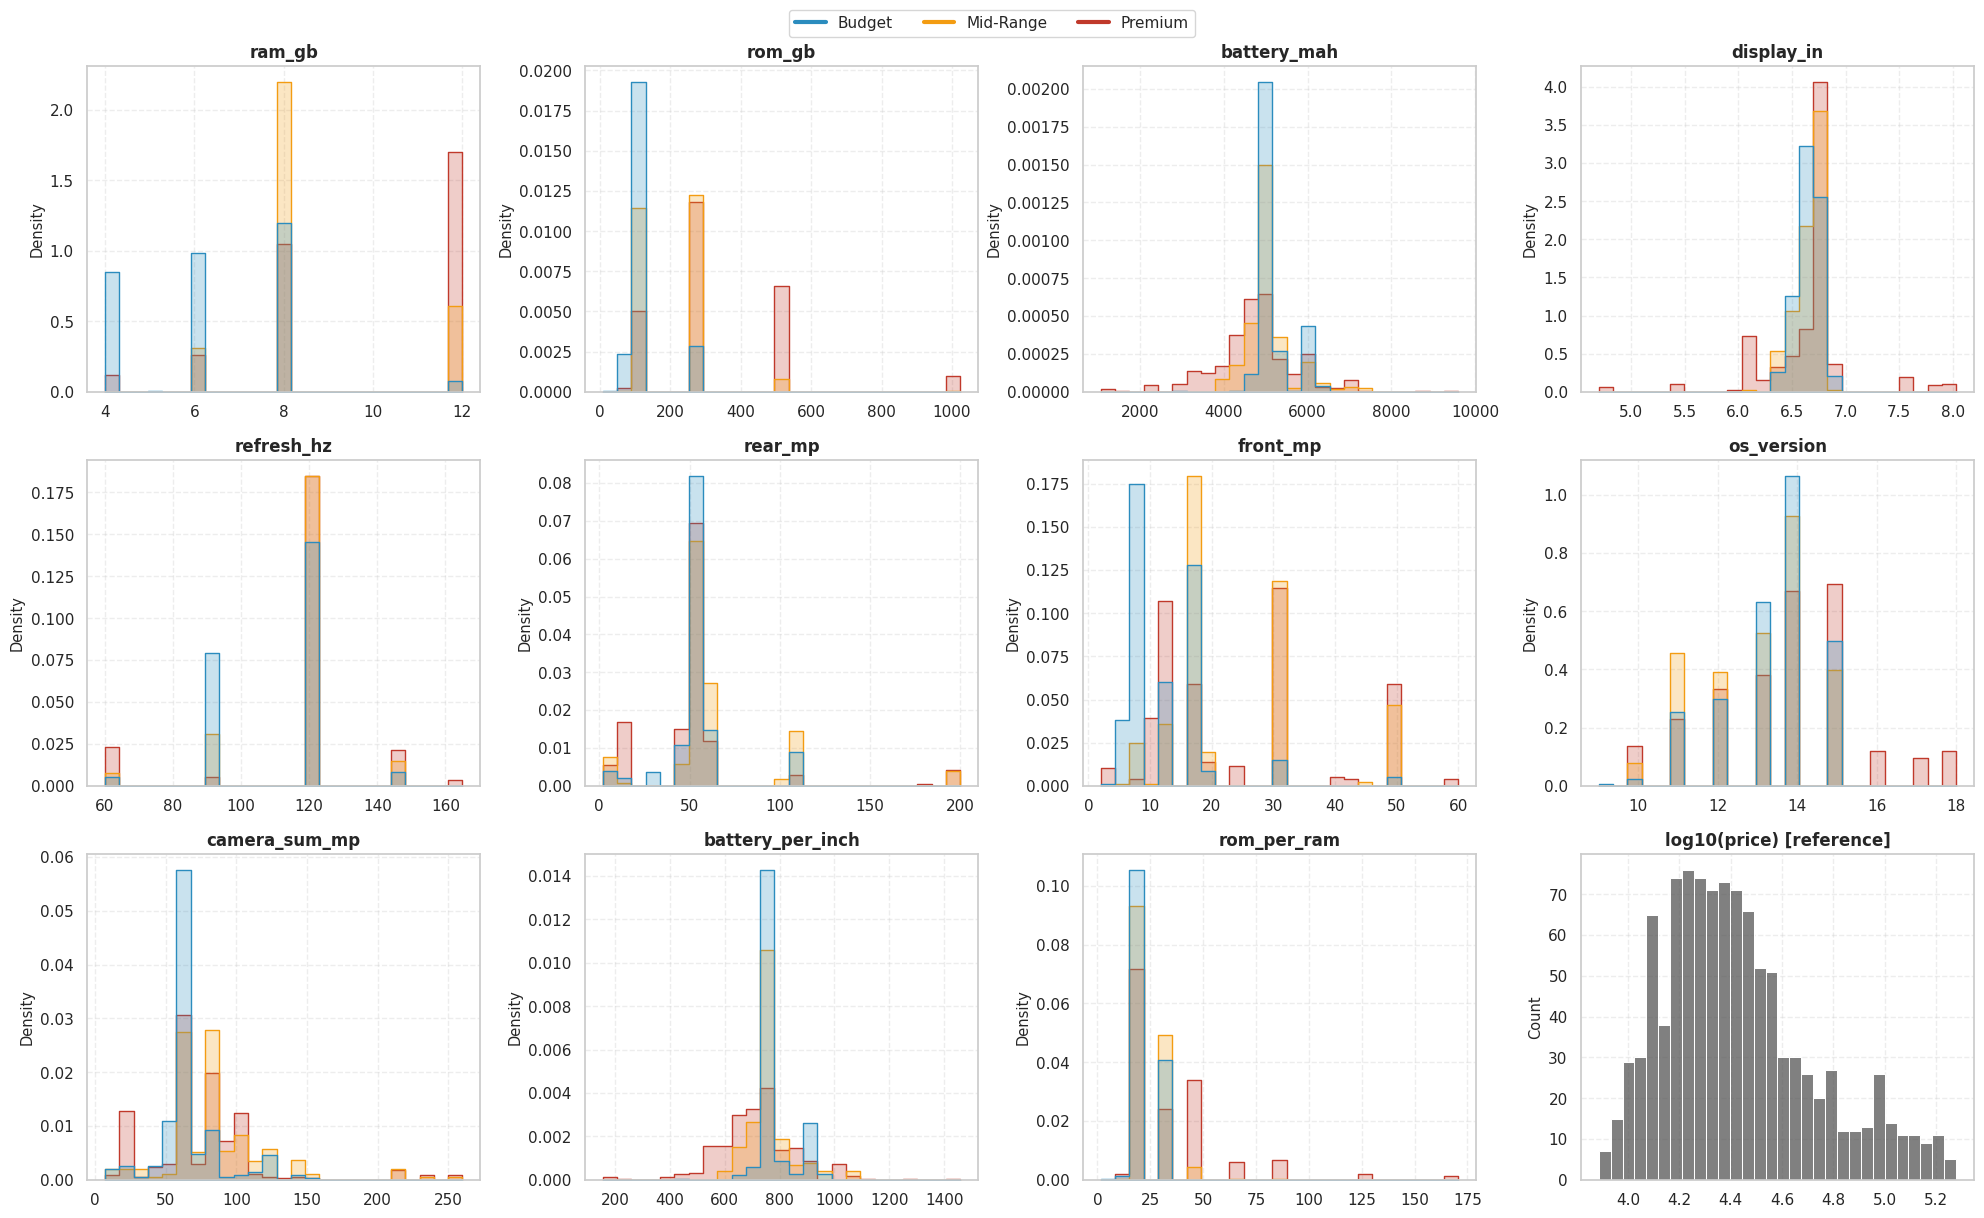

In [15]:
# FIGURE 4: Distribution of every numeric feature, split by price tier
plot_feats = ["ram_gb", "rom_gb", "battery_mah", "display_in", "refresh_hz", "rear_mp",
              "front_mp", "os_version", "camera_sum_mp", "battery_per_inch", "rom_per_ram"]
plot_df = X[plot_feats].copy(); plot_df["price_tier"] = df["price_tier"].values

fig, axes = plt.subplots(3, 4, figsize=(20, 12)); axes = axes.ravel()
for ax, col in zip(axes, plot_feats):
    sns.histplot(data=plot_df, x=col, hue="price_tier", hue_order=TIER_ORDER, palette=TIER_COLORS,
                 element="step", stat="density", common_norm=False, bins=25, ax=ax, legend=False)
    ax.set_title(col, fontweight="bold"); ax.set_xlabel("")
sns.histplot(logp, bins=30, color="#555555", ax=axes[11]); axes[11].set_title("log10(price) [reference]", fontweight="bold"); axes[11].set_xlabel("")
handles = [plt.Line2D([0], [0], color=TIER_COLORS[t], lw=3) for t in TIER_ORDER]
fig.legend(handles, TIER_ORDER, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.02), fontsize=11)
save_show("fig04_feature_distributions.png")

**Interpretation of Figure 4 (feature distributions by tier).**

* RAM, storage and refresh rate take only a handful of discrete values, so their histograms are spikes rather than smooth curves.
* **RAM and storage separate the tiers best**: the Budget curve sits on low values, Premium on high values, with Mid-Range in between and overlapping both.
* **Battery, display size, refresh rate and rear camera overlap almost completely** across tiers. Nearly every phone has a 120 Hz screen and a 50 MP main camera, so those features have little room to discriminate.
* The engineered `battery_per_inch` ratio separates the tiers a little better than raw `battery_mah` (epsilon-squared 0.11 vs 0.08, see Part F), which motivated including it.

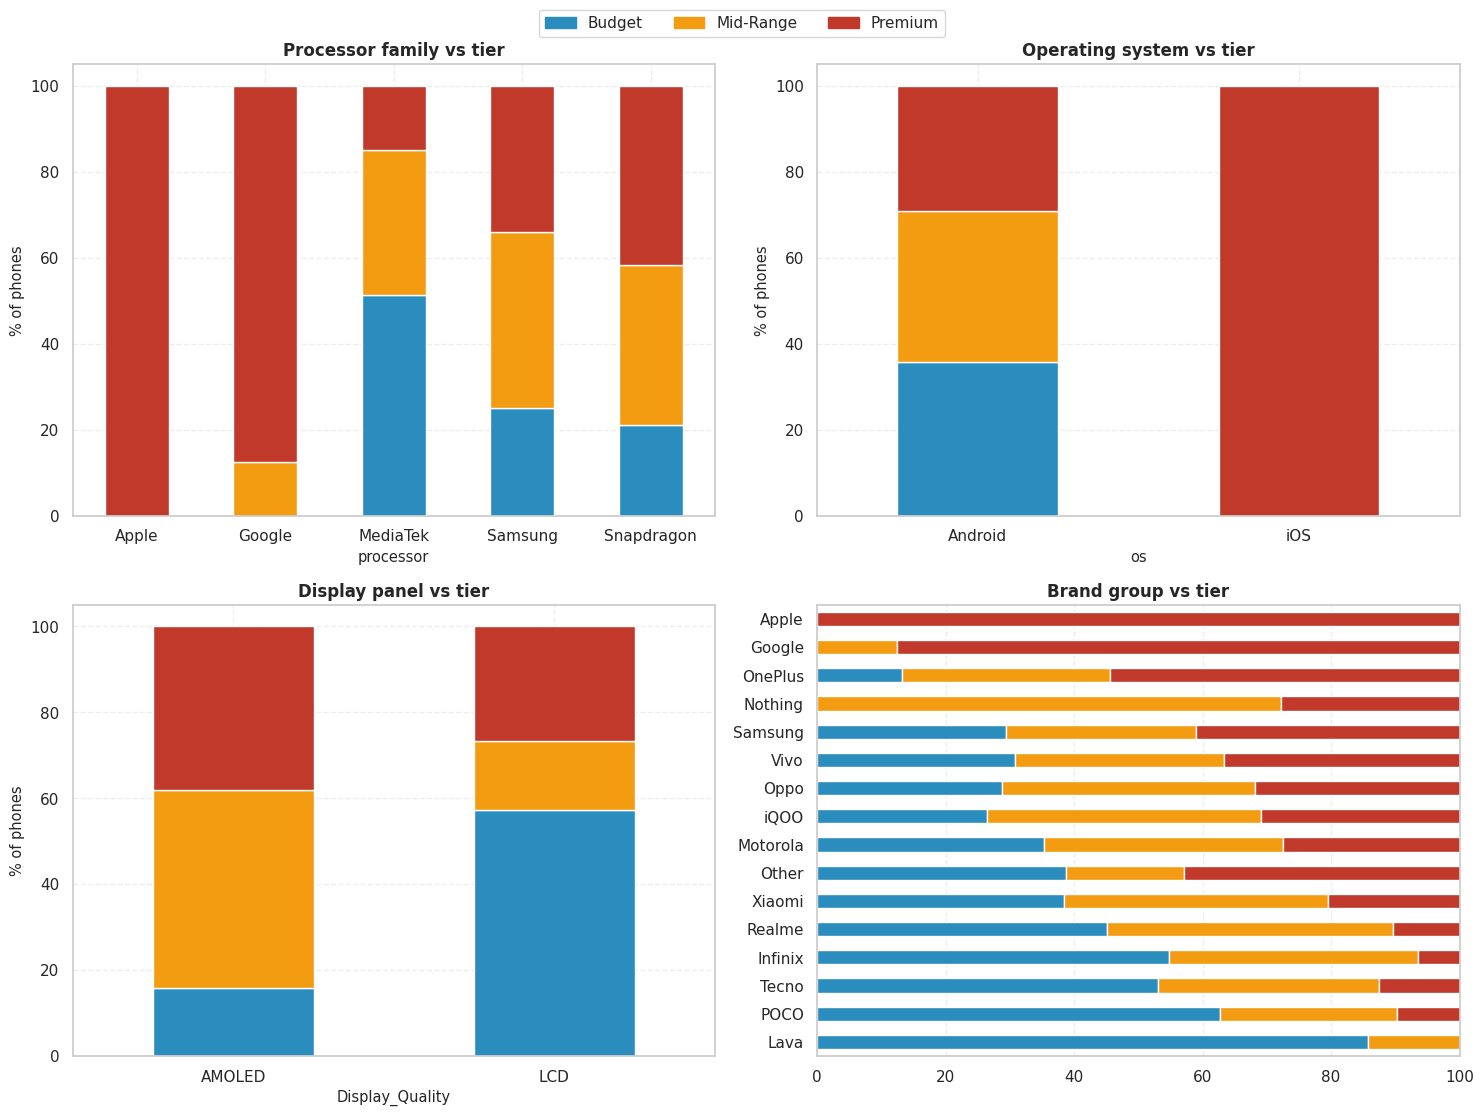

price_tier,Budget,Mid-Range,Premium
processor,,,
Apple,0.0,0.0,100.0
Google,0.0,12.5,87.5
MediaTek,51.4,33.6,15.0
Samsung,25.0,41.1,33.9
Snapdragon,21.1,37.2,41.7


In [16]:
# FIGURE 5: Categorical drivers of price tier (100% stacked bars)
def stacked(ax, col, title, order=None):
    ct = pd.crosstab(df[col], df["price_tier"], normalize="index")[TIER_ORDER] * 100
    if order is not None: ct = ct.reindex(order)
    ct.plot(kind="barh" if len(ct) > 6 else "bar", stacked=True, color=[TIER_COLORS[t] for t in TIER_ORDER],
            edgecolor="white", ax=ax, legend=False)
    ax.set_title(title, fontweight="bold"); ax.set_xlabel("") if len(ct) > 6 else ax.set_ylabel("% of phones")
    if len(ct) <= 6: ax.tick_params(axis="x", rotation=0)
    ax.set_ylabel("") if len(ct) > 6 else None
    return ct

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
ct_cpu = stacked(axes[0, 0], "processor", "Processor family vs tier")
df["os"] = np.where(df["is_ios"] == 1, "iOS", "Android")
ct_os  = stacked(axes[0, 1], "os", "Operating system vs tier")
ct_dq  = stacked(axes[1, 0], "Display_Quality", "Display panel vs tier")
ord_b  = df.groupby("brand_group")["price_inr"].median().sort_values().index
ct_br  = stacked(axes[1, 1], "brand_group", "Brand group vs tier", order=list(ord_b))
fig.legend([plt.Rectangle((0, 0), 1, 1, color=TIER_COLORS[t]) for t in TIER_ORDER], TIER_ORDER,
           loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.02), fontsize=11)
save_show("fig05_categorical_vs_tier.png")
display(ct_cpu.round(1))

**Interpretation of Figure 5 (categorical features vs tier).**

* **Processor:** Apple phones are 100% Premium and Google (Tensor) phones 87.5% Premium. MediaTek is the Budget workhorse (51.4% Budget, only 15.0% Premium), while Snapdragon leans Premium (41.7%) but still appears in every tier.
* **Operating system:** all iOS phones are Premium; Android appears in all three tiers. iOS accounts for 17.8% of the Premium class and none of the others.
* **Display panel:** AMOLED share rises from **27.3%** of Budget phones to **79.3%** of Mid-Range phones and **65.9%** of Premium phones. The panel is the categorical feature most associated with tier (Cramer's V = 0.447, see Part F), mostly because it separates Budget from the rest.
* The brand panel repeats the message of Figure 3: only a few brands (Apple, Tecno, Infinix, Lava) are one-sided.

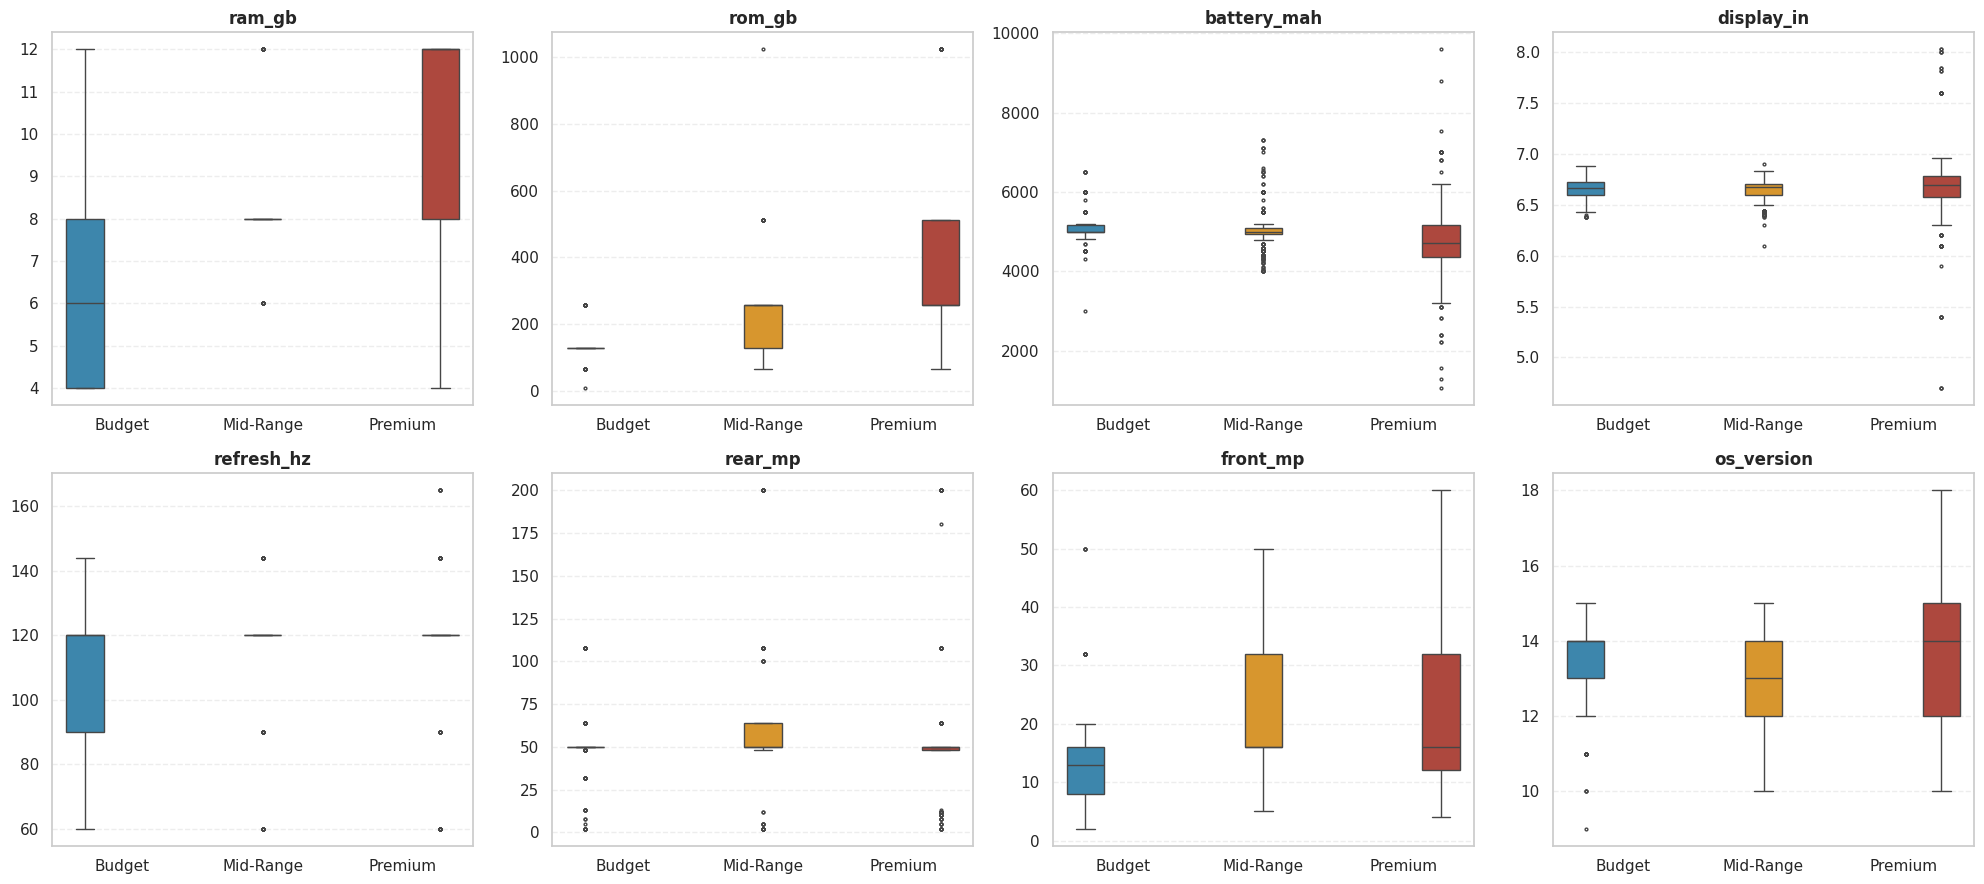

Median value of each core spec per tier:


,ram_gb,rom_gb,battery_mah,display_in,refresh_hz,rear_mp,front_mp,os_version
price_tier,,,,,,,,
Budget,6.0,128.0,5000.0,6.67,120.0,50.0,13.0,14.0
Mid-Range,8.0,256.0,5000.0,6.68,120.0,50.0,16.0,13.0
Premium,12.0,256.0,4720.0,6.70,120.0,50.0,16.0,14.0


In [17]:
# FIGURE 6: Box plots of the eight core specs by tier
core = ["ram_gb", "rom_gb", "battery_mah", "display_in", "refresh_hz", "rear_mp", "front_mp", "os_version"]
fig, axes = plt.subplots(2, 4, figsize=(20, 9)); axes = axes.ravel()
for ax, col in zip(axes, core):
    sns.boxplot(data=plot_df, x="price_tier", y=col, order=TIER_ORDER, hue="price_tier", palette=TIER_COLORS,
                legend=False, ax=ax, fliersize=2)
    ax.set_title(col, fontweight="bold"); ax.set_xlabel(""); ax.set_ylabel("")
save_show("fig06_specs_by_tier_boxplots.png")

print("Median value of each core spec per tier:")
display(plot_df.groupby("price_tier", observed=True)[core].median().round(2))

**Interpretation of Figure 6 (core specs by tier).**

| Spec (median) | Budget | Mid-Range | Premium |
|---|---|---|---|
| RAM (GB) | 6 | 8 | 12 |
| Storage (GB) | 128 | 256 | 256 |
| Battery (mAh) | 5,000 | 5,000 | 4,720 |
| Refresh rate (Hz) | 120 | 120 | 120 |
| Rear camera (MP) | 50 | 50 | 50 |
| Front camera (MP) | 13 | 16 | 16 |

* RAM climbs steadily with tier (6 to 8 to 12 GB). Storage separates Budget from the rest but not Mid-Range from Premium.
* **Premium phones have slightly smaller batteries** (4,720 mAh vs 5,000 mAh): flagships often trade battery size for slim design, and iPhones (about 18% of the Premium class) have comparatively small batteries. Large batteries are a *Budget/Mid-Range* trait in this data.
* Refresh rate and rear camera MP have identical medians everywhere, so on their own they carry almost no tier information.

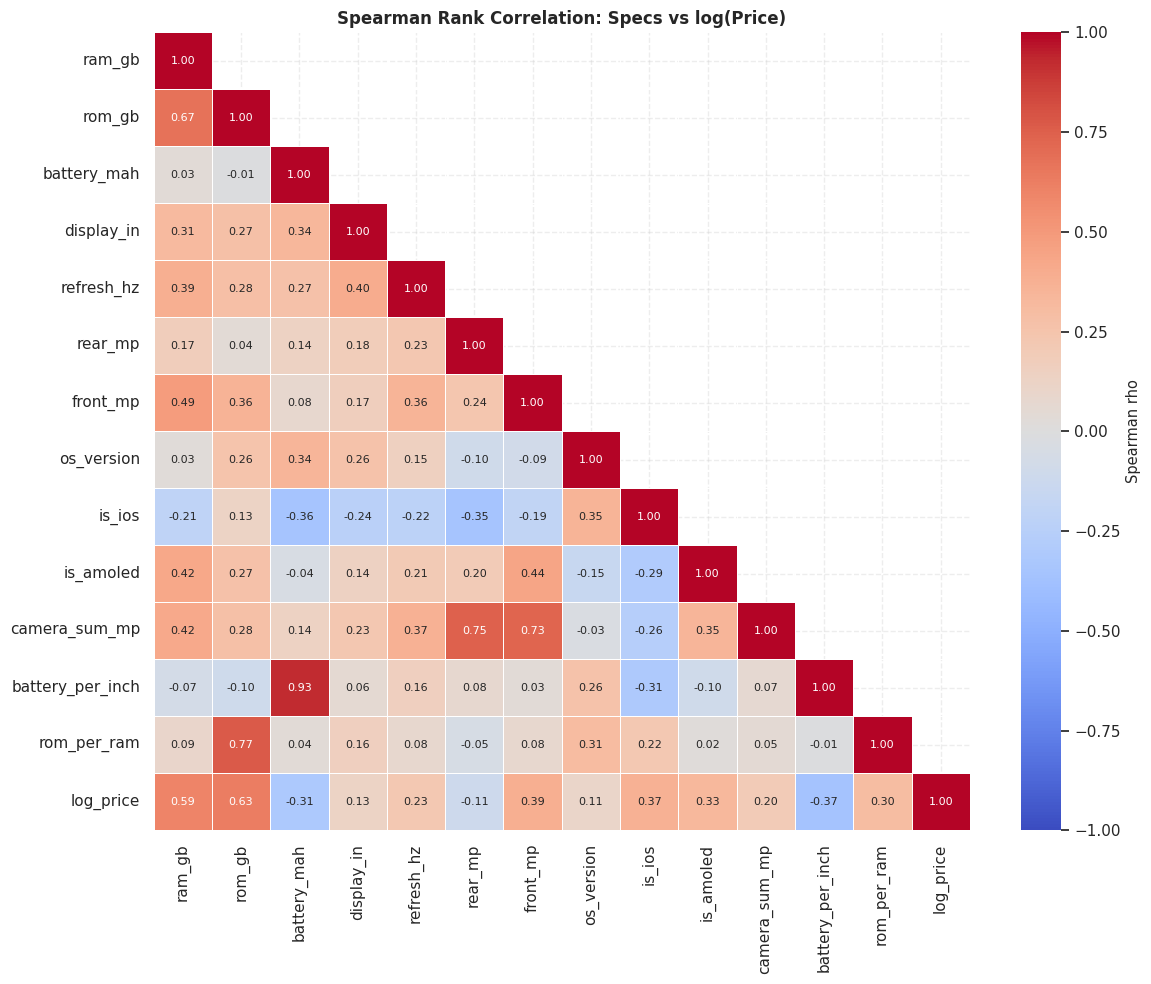

Rank correlation with price (strongest first):


,spearman_rho
rom_gb,0.629
ram_gb,0.595
front_mp,0.385
is_ios,0.368
battery_per_inch,-0.367
is_amoled,0.334
battery_mah,-0.315
rom_per_ram,0.299
refresh_hz,0.225
camera_sum_mp,0.198


In [18]:
# FIGURE 7: Spearman correlation heatmap (features + log price)
corr_df = X[NUM_COLS].copy(); corr_df["log_price"] = logp.values
corr = corr_df.corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
plt.figure(figsize=(12, 10))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.4,
            linecolor="white", cbar_kws={"label": "Spearman rho"}, annot_kws={"size": 8})
plt.title("Spearman Rank Correlation: Specs vs log(Price)", fontweight="bold")
save_show("fig07_correlation_heatmap.png")

print("Rank correlation with price (strongest first):")
display(corr["log_price"].drop("log_price").sort_values(key=abs, ascending=False).round(3).to_frame("spearman_rho"))

**Interpretation of Figure 7 (Spearman correlation).**

* **Storage (rho = 0.63) and RAM (rho = 0.60)** are the strongest positive correlates of price. Front camera MP (0.39), iOS (0.37) and AMOLED (0.33) follow.
* **Negative correlations:** `battery_per_inch` (-0.37) and `battery_mah` (-0.32). Bigger batteries mean *cheaper* phones in this data, an example of why correlation is not a causal story: manufacturers fit big batteries to inexpensive models while premium phones prioritise slimness.
* Rear camera MP (-0.11) is slightly negative: headline megapixels are a marketing spec that cheaper phones often match.
* No single feature exceeds |rho| = 0.63, so no one spec determines price. Models must combine many weak-to-moderate signals.

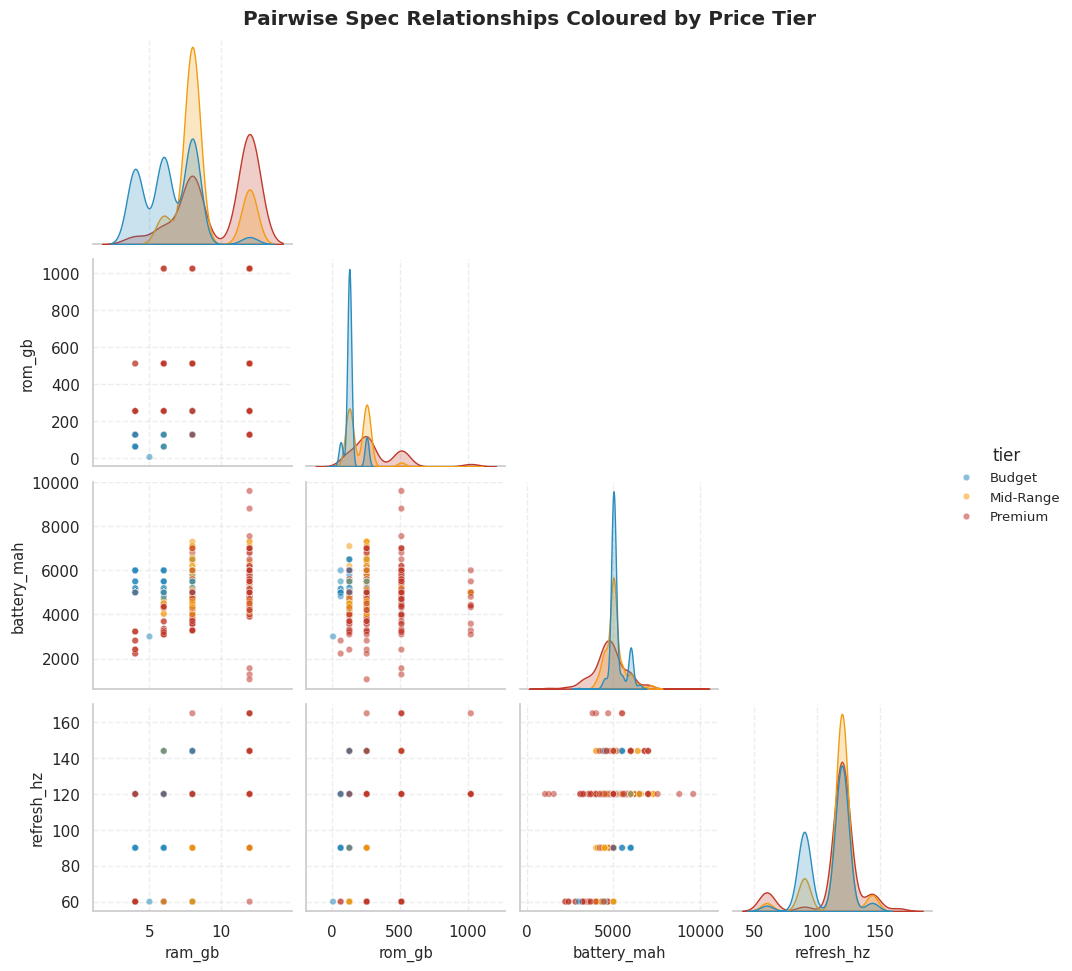

In [19]:
# FIGURE 8: Pairwise relationships between the four most price-related specs
pp = X[["ram_gb", "rom_gb", "battery_mah", "refresh_hz"]].copy(); pp["tier"] = df["price_tier"].astype(str).values
g = sns.pairplot(pp, hue="tier", hue_order=TIER_ORDER, palette=TIER_COLORS, corner=True,
                 plot_kws={"alpha": 0.55, "s": 22}, diag_kind="kde", height=2.4)
g.figure.suptitle("Pairwise Spec Relationships Coloured by Price Tier", y=1.01, fontweight="bold")
save_show("fig08_pairplot.png", tight=False)

**Interpretation of Figure 8 (pairplot).**

* Points sit on a grid because RAM, storage and refresh rate are discrete. Premium (red) clusters at high RAM and high storage; Budget (blue) at low RAM and 128 GB or less.
* In the RAM-versus-storage panel the colours overlap in the middle (8 GB / 128-256 GB), which is exactly where Mid-Range phones live and why that tier will be hardest to classify.
* Battery and refresh rate show almost no colour separation, consistent with the box plots.
* On the diagonal density plots, RAM and storage show the clearest differences between the three tier curves.

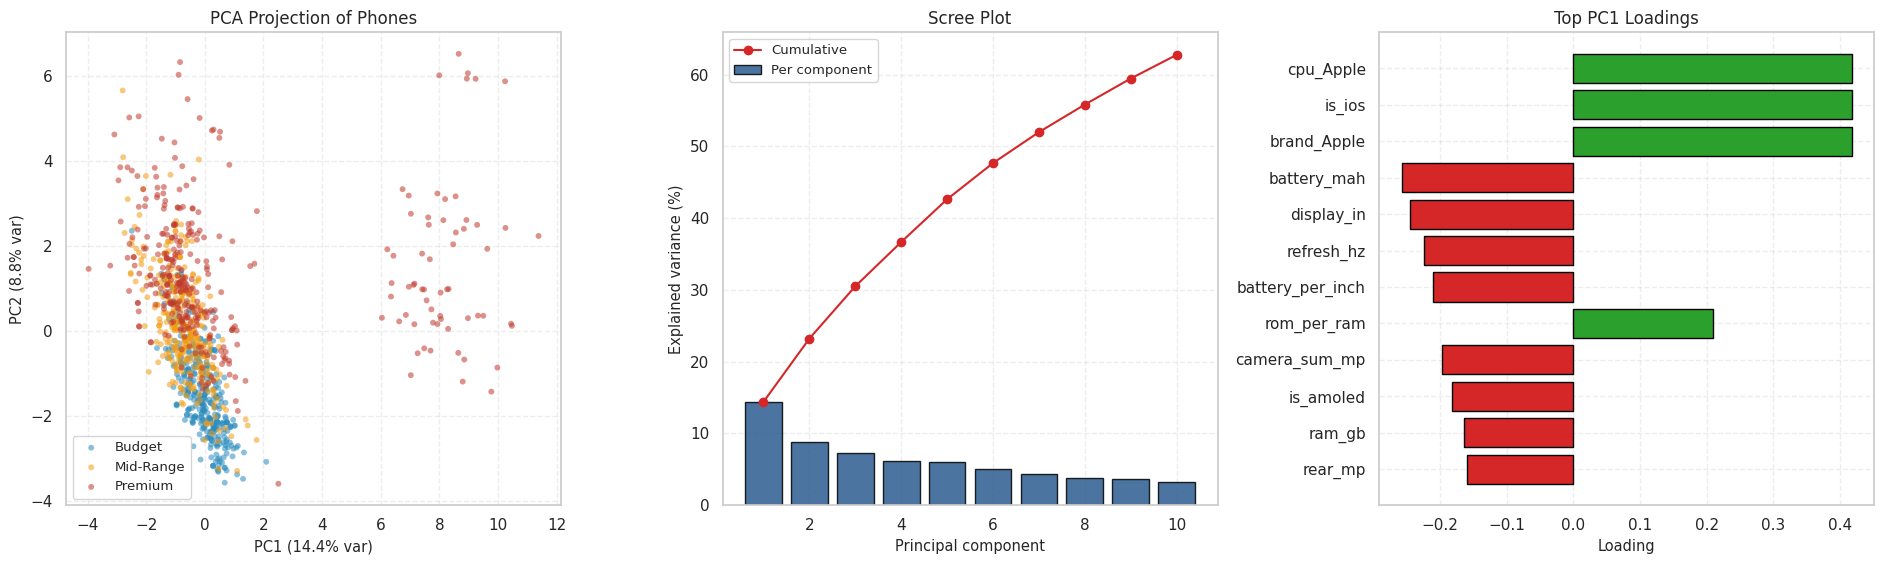

First 2 components explain 23.2% of variance; first 5 explain 42.6%.


In [20]:
# FIGURE 9: PCA projection, how separable are the tiers in feature space?
Xi = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(X), columns=X.columns)
Xs = StandardScaler().fit_transform(Xi)
pca = PCA(n_components=10, random_state=RANDOM_SEED).fit(Xs)
Z = pca.transform(Xs)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.8))
for t in TIER_ORDER:
    m = (df["price_tier"] == t).values
    axes[0].scatter(Z[m, 0], Z[m, 1], s=18, alpha=0.55, color=TIER_COLORS[t], label=t, edgecolor="none")
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)"); axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)")
axes[0].set_title("PCA Projection of Phones"); axes[0].legend()

axes[1].bar(range(1, 11), pca.explained_variance_ratio_ * 100, color="#2b5c8f", edgecolor="black", alpha=0.85, label="Per component")
axes[1].plot(range(1, 11), np.cumsum(pca.explained_variance_ratio_) * 100, "o-", color="#d62728", label="Cumulative")
axes[1].set_xlabel("Principal component"); axes[1].set_ylabel("Explained variance (%)"); axes[1].set_title("Scree Plot"); axes[1].legend()

load = pd.Series(pca.components_[0], index=X.columns); top = load.reindex(load.abs().sort_values(ascending=False).head(12).index)[::-1]
axes[2].barh(top.index, top.values, color=np.where(top.values > 0, "#2ca02c", "#d62728"), edgecolor="black")
axes[2].set_title("Top PC1 Loadings"); axes[2].set_xlabel("Loading")
save_show("fig09_pca_projection.png")
print(f"First 2 components explain {pca.explained_variance_ratio_[:2].sum()*100:.1f}% of variance; first 5 explain {pca.explained_variance_ratio_[:5].sum()*100:.1f}%.")

**Interpretation of Figure 9 (PCA).**

* The first two components explain just **23.2%** of the variance (42.6% for five), so the feature space is high-dimensional with no dominant direction.
* **PC1 is essentially the Apple/iOS axis** (top loadings: `cpu_Apple`, `is_ios`, `brand_Apple`). The isolated cluster on the right of the left panel is the iPhones, all Premium.
* Among Android phones, **Budget (blue) sits lower on PC2**, while Mid-Range (orange) and Premium (red) overlap heavily in the dense cluster. A straight line in this 2-D view cannot separate the tiers, which supports using non-linear, tree-based models.

## Part F. Statistical Hypothesis Testing

In [21]:
# Numeric features: Kruskal-Wallis across the 3 tiers, with epsilon-squared effect size
rows = []
n = len(df)
for col in NUM_COLS:
    groups = [X.loc[df["price_tier"] == t, col].dropna() for t in TIER_ORDER]
    h, p = stats.kruskal(*groups)
    eps2 = h * (n + 1) / (n**2 - 1)
    rows.append({"feature": col, "median_Budget": groups[0].median(), "median_Mid": groups[1].median(),
                 "median_Premium": groups[2].median(), "H": round(h, 1), "p_value": p, "epsilon_sq": round(eps2, 3)})
kw = pd.DataFrame(rows).sort_values("epsilon_sq", ascending=False).set_index("feature")
kw["significant (p<0.001)"] = kw["p_value"] < 0.001
kw["p_value"] = kw["p_value"].map(lambda v: f"{v:.2e}")
display(kw.round(2))

,median_Budget,median_Mid,median_Premium,H,p_value,epsilon_sq,significant (p<0.001)
feature,,,,,,,
rom_gb,128.00,256.00,256.00,368.2,1.12e-80,0.35,True
ram_gb,6.00,8.00,12.00,349.8,1.08e-76,0.33,True
front_mp,13.00,16.00,16.00,245.4,5.09e-54,0.23,True
is_amoled,0.00,1.00,1.00,209.1,3.96e-46,0.20,True
camera_sum_mp,63.00,80.00,66.00,137.2,1.63e-30,0.13,True
is_ios,0.00,0.00,0.00,132.0,2.13e-29,0.13,True
battery_per_inch,757.58,746.27,716.42,118.2,2.19e-26,0.11,True
rom_per_ram,21.33,21.33,32.00,97.2,7.75e-22,0.09,True
battery_mah,5000.00,5000.00,4720.00,81.7,1.81e-18,0.08,True


In [22]:
# Categorical features: chi-square test of independence with Cramer's V
def cramers_v(ct):
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    nn = ct.values.sum(); k = min(ct.shape) - 1
    return chi2, p, dof, np.sqrt(chi2 / (nn * k))

cat_rows = []
for col, label in [("brand_group", "Brand group"), ("processor", "Processor family"),
                   ("Display_Quality", "Display panel"), ("os", "Operating system")]:
    chi2, p, dof, v = cramers_v(pd.crosstab(df[col], df["price_tier"]))
    cat_rows.append({"feature": label, "chi2": round(chi2, 1), "dof": dof, "p_value": f"{p:.2e}", "cramers_V": round(v, 3)})
chi_tbl = pd.DataFrame(cat_rows).set_index("feature").sort_values("cramers_V", ascending=False)
display(chi_tbl)

,chi2,dof,p_value,cramers_V
feature,,,,
Display panel,209.3,2,3.59e-46,0.447
Brand group,302.9,30,7.06e-47,0.380
Processor family,273.0,8,2.25e-54,0.361
Operating system,132.2,2,2.00e-29,0.355


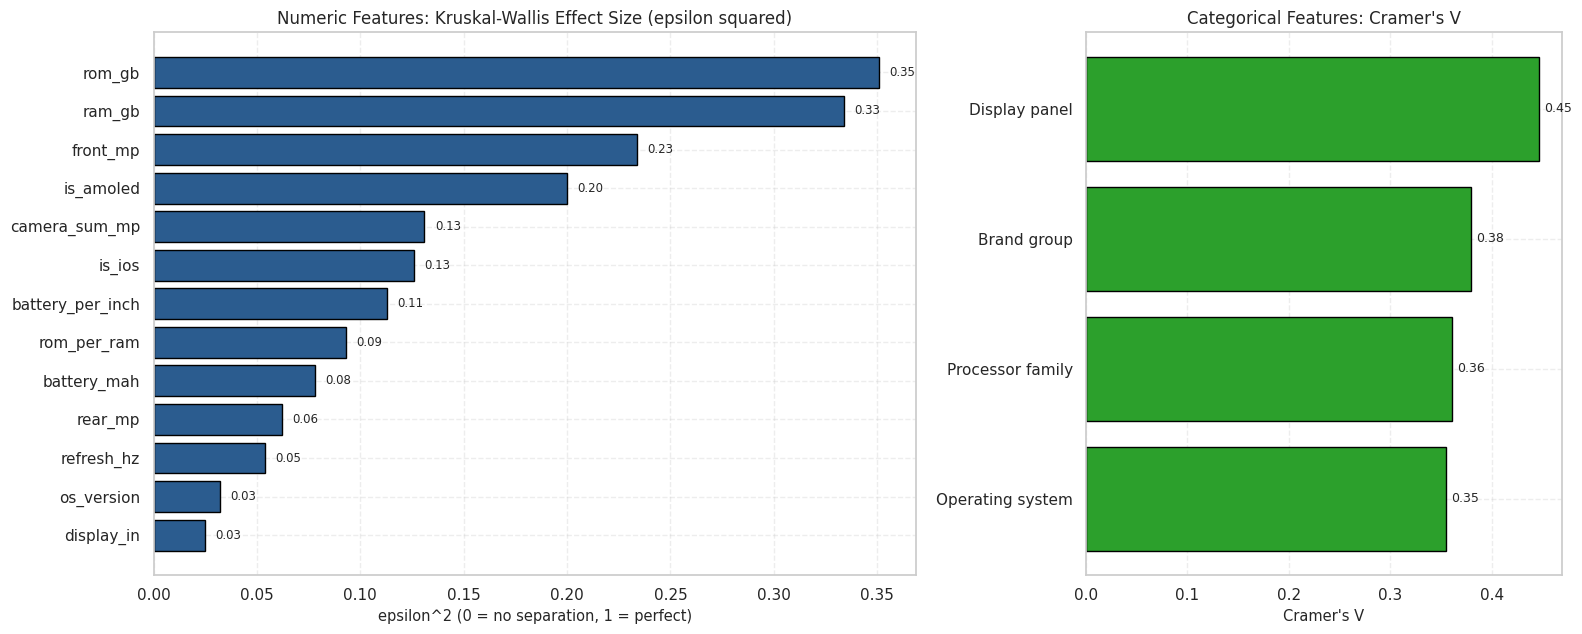

In [23]:
# FIGURE 10: Effect sizes (how strongly each feature separates the tiers)
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.6, 1]})
e = kw["epsilon_sq"].sort_values()
axes[0].barh(e.index, e.values, color="#2b5c8f", edgecolor="black")
for i, v in enumerate(e.values): axes[0].text(v + 0.005, i, f"{v:.2f}", va="center", fontsize=8.5)
axes[0].set_title("Numeric Features: Kruskal-Wallis Effect Size (epsilon squared)"); axes[0].set_xlabel("epsilon^2 (0 = no separation, 1 = perfect)")

v = chi_tbl["cramers_V"].sort_values()
axes[1].barh(v.index, v.values, color="#2ca02c", edgecolor="black")
for i, val in enumerate(v.values): axes[1].text(val + 0.005, i, f"{val:.2f}", va="center", fontsize=9)
axes[1].set_title("Categorical Features: Cramer's V"); axes[1].set_xlabel("Cramer's V")
save_show("fig10_effect_sizes.png")

**Interpretation of Figure 10 (effect sizes).**

* Every numeric feature is statistically significant at p < 0.001, but **significance is not importance** with 1,049 samples. The epsilon-squared effect size shows the practical strength: **storage (0.35) and RAM (0.33)** are large, front camera (0.23) and AMOLED (0.20) are moderate, and refresh rate (0.05), OS version (0.03) and display size (0.02) are negligible.
* For categorical features, **display panel (V = 0.45)** is the strongest, followed by brand (0.38), processor (0.36) and OS (0.36), all in the moderate-to-strong range.
* This univariate ranking is a useful sanity check before modeling; the models in Part I will show which features matter once they are combined.

## Part G. Modeling: Random Forest and Gradient Boosting
Both models sit inside a scikit-learn **Pipeline** with a median imputer, so missing camera values are imputed using *training folds only* (no leakage into validation folds). Hyperparameters are tuned with 5-fold stratified `GridSearchCV` optimising **macro-F1**, which weights the three tiers equally.

In [24]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

def make_pipe(clf):
    return Pipeline([("imputer", SimpleImputer(strategy="median")), ("clf", clf)])

best_models, best_params, grid_objs = {}, {}, {}
print("Model 1/2: RANDOM FOREST")
rf_grid = {"clf__n_estimators": [200, 400], "clf__max_depth": [None, 10, 20],
           "clf__min_samples_leaf": [1, 2, 4], "clf__max_features": ["sqrt", 0.5]}
t0 = time.time()
gs_rf = GridSearchCV(make_pipe(RandomForestClassifier(random_state=RANDOM_SEED, n_jobs=-1)), rf_grid,
                     cv=cv5, scoring="f1_macro", n_jobs=-1).fit(X_train, y_train)
best_models["Random Forest"], best_params["Random Forest"], grid_objs["Random Forest"] = gs_rf.best_estimator_, gs_rf.best_params_, gs_rf
n_fits = len(gs_rf.cv_results_["params"]) * 5
print(f"  candidates x folds : {len(gs_rf.cv_results_['params'])} x 5 = {n_fits} fits in {time.time()-t0:.0f}s")
print("  best params        :", {k.replace('clf__', ''): v for k, v in gs_rf.best_params_.items()})
print(f"  best CV macro-F1   : {gs_rf.best_score_:.4f}")

Model 1/2: RANDOM FOREST
  candidates x folds : 36 x 5 = 180 fits in 62s
  best params        : {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 200}
  best CV macro-F1   : 0.7889


In [25]:
print("Model 2/2: GRADIENT BOOSTING")
gb_grid = {"clf__n_estimators": [100, 200], "clf__learning_rate": [0.05, 0.1],
           "clf__max_depth": [2, 3, 4], "clf__subsample": [0.8, 1.0]}
t0 = time.time()
gs_gb = GridSearchCV(make_pipe(GradientBoostingClassifier(random_state=RANDOM_SEED)), gb_grid,
                     cv=cv5, scoring="f1_macro", n_jobs=-1).fit(X_train, y_train)
best_models["Gradient Boosting"], best_params["Gradient Boosting"], grid_objs["Gradient Boosting"] = gs_gb.best_estimator_, gs_gb.best_params_, gs_gb
n_fits = len(gs_gb.cv_results_["params"]) * 5
print(f"  candidates x folds : {len(gs_gb.cv_results_['params'])} x 5 = {n_fits} fits in {time.time()-t0:.0f}s")
print("  best params        :", {k.replace('clf__', ''): v for k, v in gs_gb.best_params_.items()})
print(f"  best CV macro-F1   : {gs_gb.best_score_:.4f}")

Model 2/2: GRADIENT BOOSTING
  candidates x folds : 24 x 5 = 120 fits in 49s
  best params        : {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 200, 'subsample': 1.0}
  best CV macro-F1   : 0.8051


In [26]:
# Top-8 hyper-parameter combinations for each model
for name, gs in grid_objs.items():
    res = pd.DataFrame(gs.cv_results_).sort_values("rank_test_score").head(8)
    cols = [c for c in res.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score", "mean_fit_time"]
    out = res[cols].rename(columns=lambda c: c.replace("param_clf__", ""))
    print(f"\n{name}: top 8 of {len(gs.cv_results_['params'])} candidates")
    display(out.round(4).reset_index(drop=True))


Random Forest: top 8 of 36 candidates


,max_depth,max_features,min_samples_leaf,n_estimators,mean_test_score,std_test_score,mean_fit_time
0,10,sqrt,2,200,0.7889,0.0307,0.1929
1,10,sqrt,2,400,0.7820,0.0311,0.3642
2,None,sqrt,2,200,0.7819,0.0319,0.1899
3,20,sqrt,2,200,0.7819,0.0319,0.2227
4,10,sqrt,1,200,0.7806,0.0235,0.1959
5,None,sqrt,2,400,0.7793,0.0306,0.3794
6,20,sqrt,2,400,0.7793,0.0306,0.3638
7,None,sqrt,1,200,0.7782,0.0211,0.2040



Gradient Boosting: top 8 of 24 candidates


,learning_rate,max_depth,n_estimators,subsample,mean_test_score,std_test_score,mean_fit_time
0,0.10,2,200,1.0,0.8051,0.0161,0.4091
1,0.10,3,100,0.8,0.8008,0.0264,0.2569
2,0.05,3,200,0.8,0.8008,0.0207,0.4871
3,0.10,3,200,0.8,0.7978,0.0146,0.5097
4,0.05,4,200,0.8,0.7978,0.0246,0.6467
5,0.05,4,100,1.0,0.7960,0.0306,0.3510
6,0.05,2,200,0.8,0.7956,0.0273,0.3727
7,0.10,3,100,1.0,0.7955,0.0213,0.2735


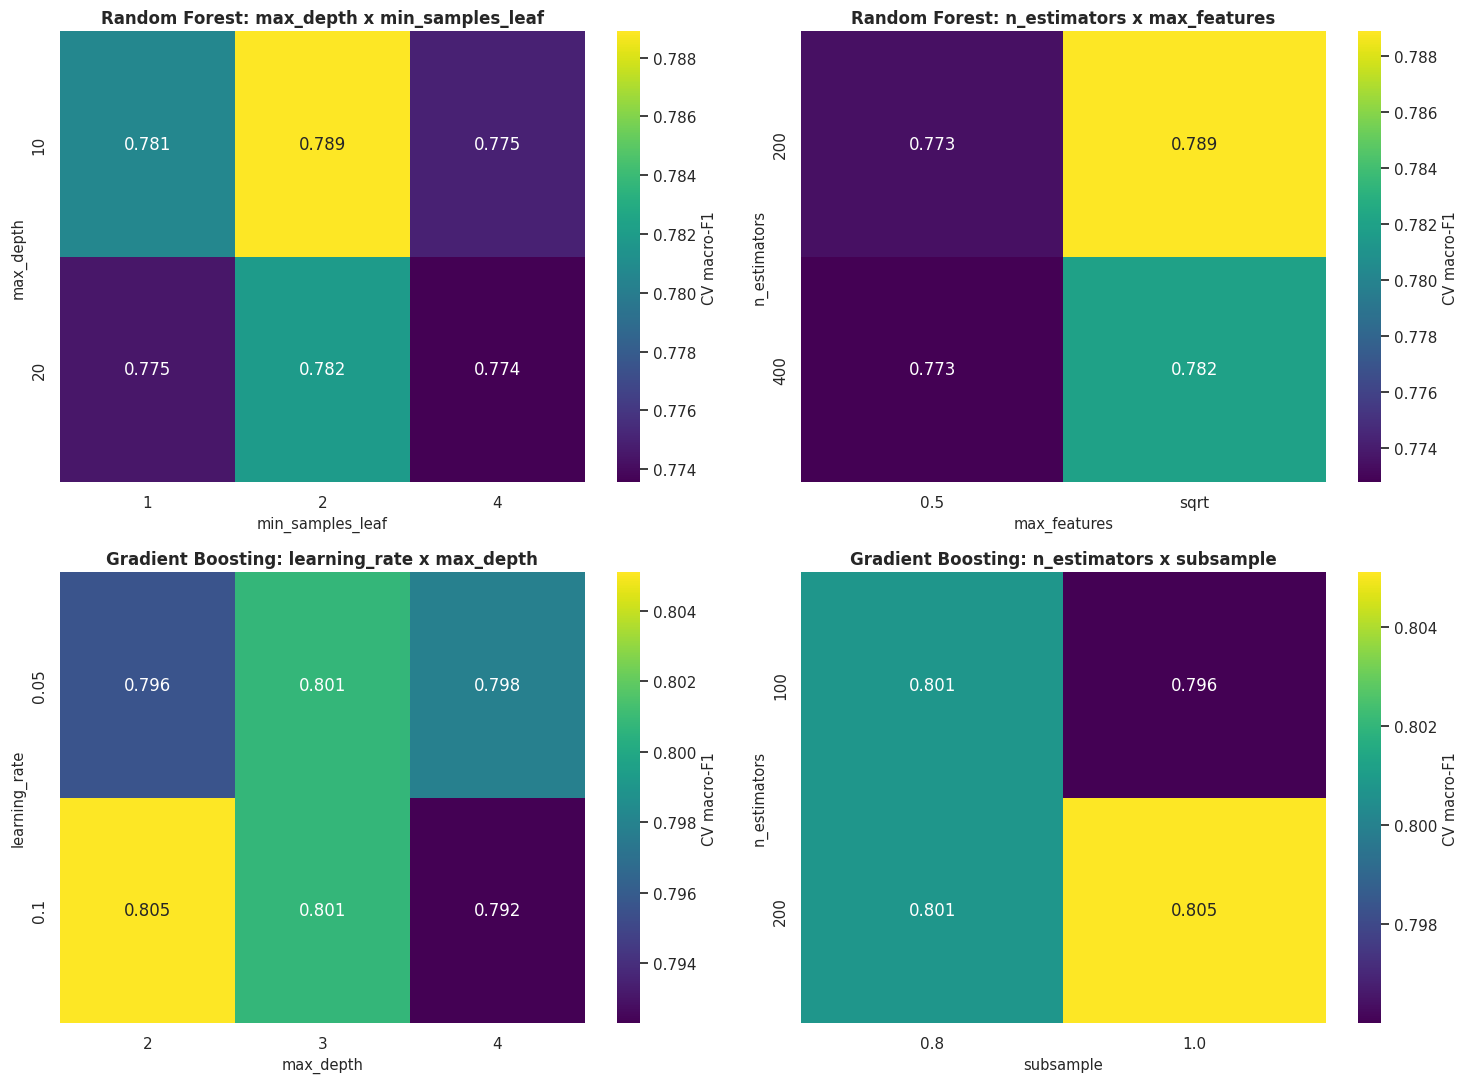

In [27]:
# FIGURE 11: Hyper-parameter search landscape (best CV macro-F1 for each pair of settings)
def grid_heat(gs, p1, p2, ax, title):
    res = pd.DataFrame(gs.cv_results_)
    res["a"] = res[f"param_clf__{p1}"].astype(str); res["b"] = res[f"param_clf__{p2}"].astype(str)
    piv = res.groupby(["a", "b"])["mean_test_score"].max().unstack()
    sns.heatmap(piv, annot=True, fmt=".3f", cmap="viridis", cbar_kws={"label": "CV macro-F1"}, ax=ax)
    ax.set_title(title, fontweight="bold"); ax.set_ylabel(p1); ax.set_xlabel(p2)

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
grid_heat(gs_rf, "max_depth", "min_samples_leaf", axes[0, 0], "Random Forest: max_depth x min_samples_leaf")
grid_heat(gs_rf, "n_estimators", "max_features", axes[0, 1], "Random Forest: n_estimators x max_features")
grid_heat(gs_gb, "learning_rate", "max_depth", axes[1, 0], "Gradient Boosting: learning_rate x max_depth")
grid_heat(gs_gb, "n_estimators", "subsample", axes[1, 1], "Gradient Boosting: n_estimators x subsample")
save_show("fig11_hyperparameter_heatmaps.png")

**Interpretation of Figure 11 (hyper-parameter search).**

* The landscape is **flat**: the 8 best Random Forest settings span only 0.778 to 0.789 macro-F1, and the 8 best Gradient Boosting settings 0.796 to 0.805. Neither model is fragile to its settings.
* Best Random Forest: 200 trees, `max_depth = 10`, `min_samples_leaf = 2`, `max_features = sqrt` (CV macro-F1 = 0.789). Shallower trees with leaf size 2 and `sqrt` feature sampling beat unrestricted trees.
* Best Gradient Boosting: 200 trees, learning rate 0.1, **`max_depth = 2`**, no subsampling (CV macro-F1 = 0.805). The preference for very shallow trees suggests price is driven by many small additive effects rather than deep interactions.

## Part H. Evaluation on the Held-Out Test Set

In [28]:
results, preds, probas = [], {}, {}
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

for name, model in best_models.items():
    yp, pr = model.predict(X_test), model.predict_proba(X_test)
    preds[name], probas[name] = yp, pr
    results.append({"Model": name,
                    "Accuracy": accuracy_score(y_test, yp),
                    "Balanced Acc": balanced_accuracy_score(y_test, yp),
                    "Precision (macro)": precision_score(y_test, yp, average="macro"),
                    "Recall (macro)": recall_score(y_test, yp, average="macro"),
                    "F1 (macro)": f1_score(y_test, yp, average="macro"),
                    "ROC-AUC (OvR)": roc_auc_score(y_test, pr, multi_class="ovr"),
                    "MCC": matthews_corrcoef(y_test, yp),
                    "Quad. Kappa": cohen_kappa_score(y_test, yp, weights="quadratic"),
                    "MAE (tier steps)": mean_absolute_error(y_test, yp)})
df_results = pd.DataFrame(results).set_index("Model").round(4)
display(df_results)
print("Chance-level accuracy for 3 balanced classes = 0.333")

,Accuracy,Balanced Acc,Precision (macro),Recall (macro),F1 (macro),ROC-AUC (OvR),MCC,Quad. Kappa,MAE (tier steps)
Model,,,,,,,,,
Random Forest,0.8095,0.8095,0.8078,0.8095,0.8083,0.9411,0.7146,0.8481,0.1952
Gradient Boosting,0.8000,0.8000,0.7986,0.8000,0.7990,0.9471,0.7003,0.8410,0.2048


Chance-level accuracy for 3 balanced classes = 0.333


In [29]:
for name in best_models:
    print("=" * 66); print("Classification report:", name); print("=" * 66)
    print(classification_report(y_test, preds[name], target_names=TIER_ORDER, digits=3))

Classification report: Random Forest
              precision    recall  f1-score   support

      Budget      0.851     0.900     0.875        70
   Mid-Range      0.731     0.700     0.715        70
     Premium      0.841     0.829     0.835        70

    accuracy                          0.810       210
   macro avg      0.808     0.810     0.808       210
weighted avg      0.808     0.810     0.808       210

Classification report: Gradient Boosting
              precision    recall  f1-score   support

      Budget      0.824     0.871     0.847        70
   Mid-Range      0.716     0.686     0.701        70
     Premium      0.855     0.843     0.849        70

    accuracy                          0.800       210
   macro avg      0.799     0.800     0.799       210
weighted avg      0.799     0.800     0.799       210



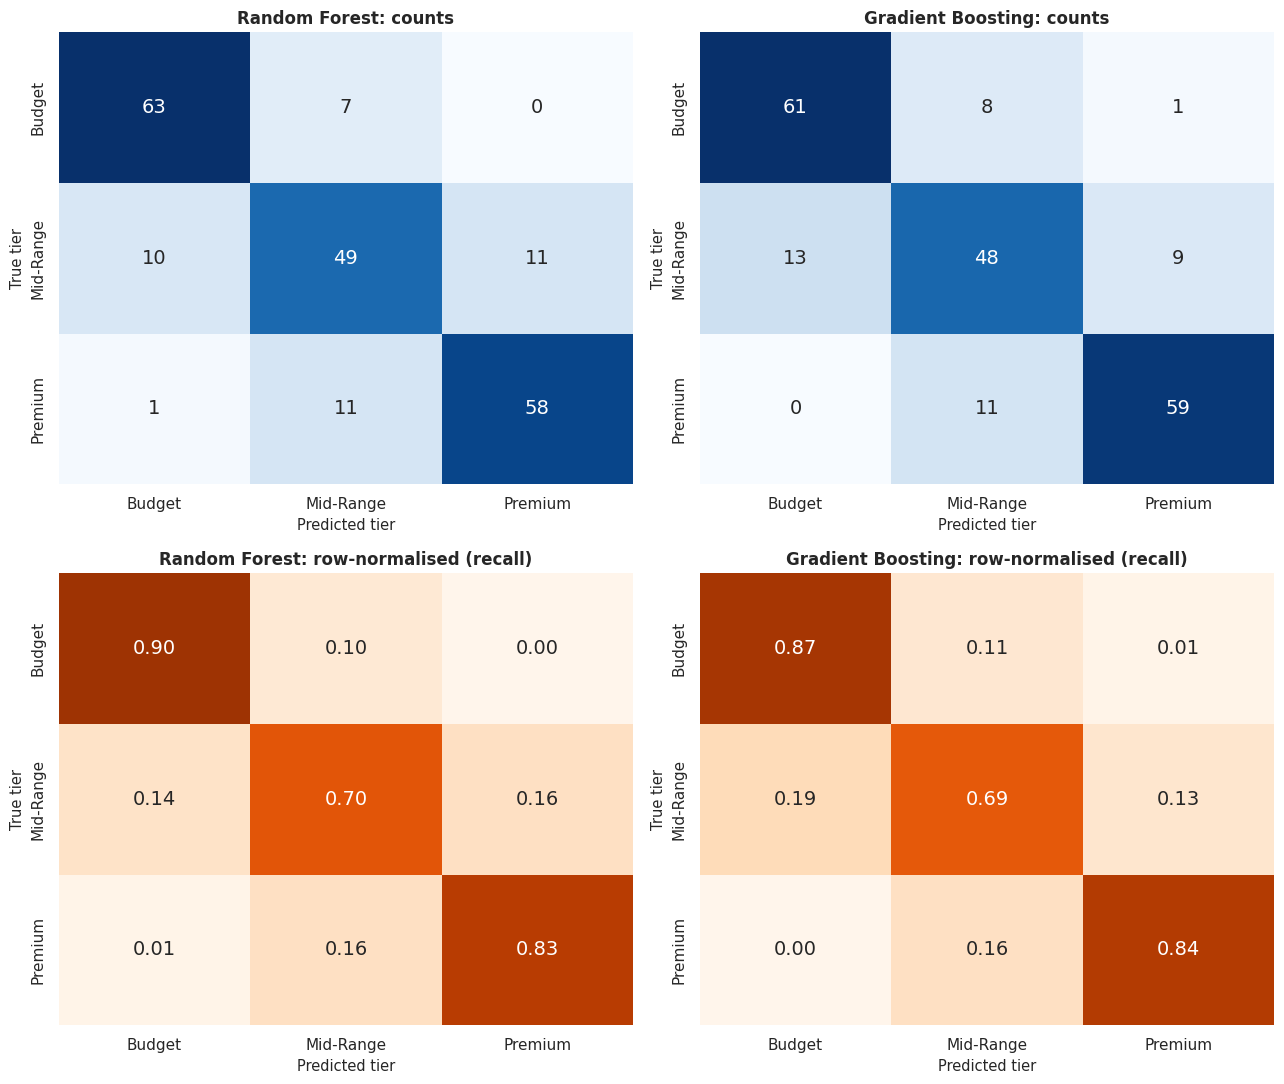

In [30]:
# FIGURE 12: Confusion matrices (counts + row-normalised)
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for j, name in enumerate(best_models):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=TIER_ORDER, yticklabels=TIER_ORDER, cbar=False,
                annot_kws={"size": 14}, ax=axes[0, j]); axes[0, j].set_title(f"{name}: counts", fontweight="bold")
    sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Oranges", vmin=0, vmax=1,
                xticklabels=TIER_ORDER, yticklabels=TIER_ORDER, cbar=False, annot_kws={"size": 14}, ax=axes[1, j])
    axes[1, j].set_title(f"{name}: row-normalised (recall)", fontweight="bold")
    for i in range(2): axes[i, j].set_xlabel("Predicted tier"); axes[i, j].set_ylabel("True tier")
save_show("fig12_confusion_matrices.png")

**Interpretation of Figure 12 (confusion matrices, 210 test phones).**

| True \ Predicted | RF Budget | RF Mid | RF Premium | GB Budget | GB Mid | GB Premium |
|---|---|---|---|---|---|---|
| Budget | 63 | 7 | 0 | 61 | 8 | 1 |
| Mid-Range | 10 | 49 | 11 | 13 | 48 | 9 |
| Premium | 1 | 11 | 58 | 0 | 11 | 59 |

* **Almost all errors are adjacent-tier mistakes.** Random Forest confuses a Budget phone for Premium **0** times and a Premium phone for Budget just **1** time; Gradient Boosting does so 1 and 0 times.
* Mid-Range is the hardest class (recall 0.70 for RF, 0.69 for GB) because it is sandwiched between the others: any phone near a price cut-off can fall either way.
* Budget (recall 0.90 / 0.87) and Premium (0.83 / 0.84) are identified well.

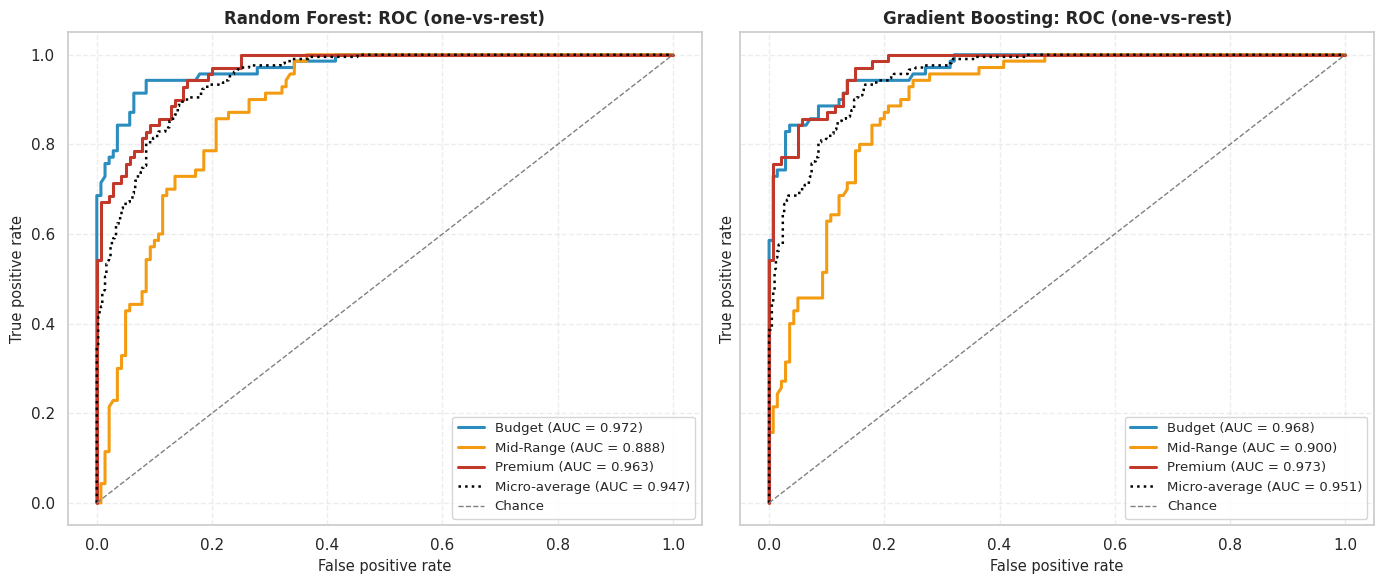

In [31]:
# FIGURE 13: ROC curves (one-vs-rest) with micro/macro averages
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for ax, name in zip(axes, best_models):
    for k, tier in enumerate(TIER_ORDER):
        fpr, tpr, _ = roc_curve(y_test_bin[:, k], probas[name][:, k])
        ax.plot(fpr, tpr, color=TIER_COLORS[tier], lw=2.2, label=f"{tier} (AUC = {auc(fpr, tpr):.3f})")
    fpr, tpr, _ = roc_curve(y_test_bin.ravel(), probas[name].ravel())
    ax.plot(fpr, tpr, color="black", lw=1.8, ls=":", label=f"Micro-average (AUC = {auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], color="grey", ls="--", lw=1, label="Chance")
    ax.set_title(f"{name}: ROC (one-vs-rest)", fontweight="bold"); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.legend(loc="lower right")
save_show("fig13_roc_curves.png")

**Interpretation of Figure 13 (ROC curves).**

* Macro OvR AUC is **0.941 (RF)** and **0.947 (GB)**. Per class, the AUCs are Budget 0.972 / 0.968, Mid-Range 0.888 / 0.900 and Premium 0.963 / 0.973 (RF / GB).
* Both models rank phones far better than chance (AUC 0.5) for every tier. The Mid-Range curve is visibly lower, matching the confusion matrix.
* The AUC ordering (GB slightly higher) differs from the accuracy ordering (RF slightly higher): AUC measures ranking quality across all thresholds, accuracy only the argmax decision, and the gaps are tiny in both cases.

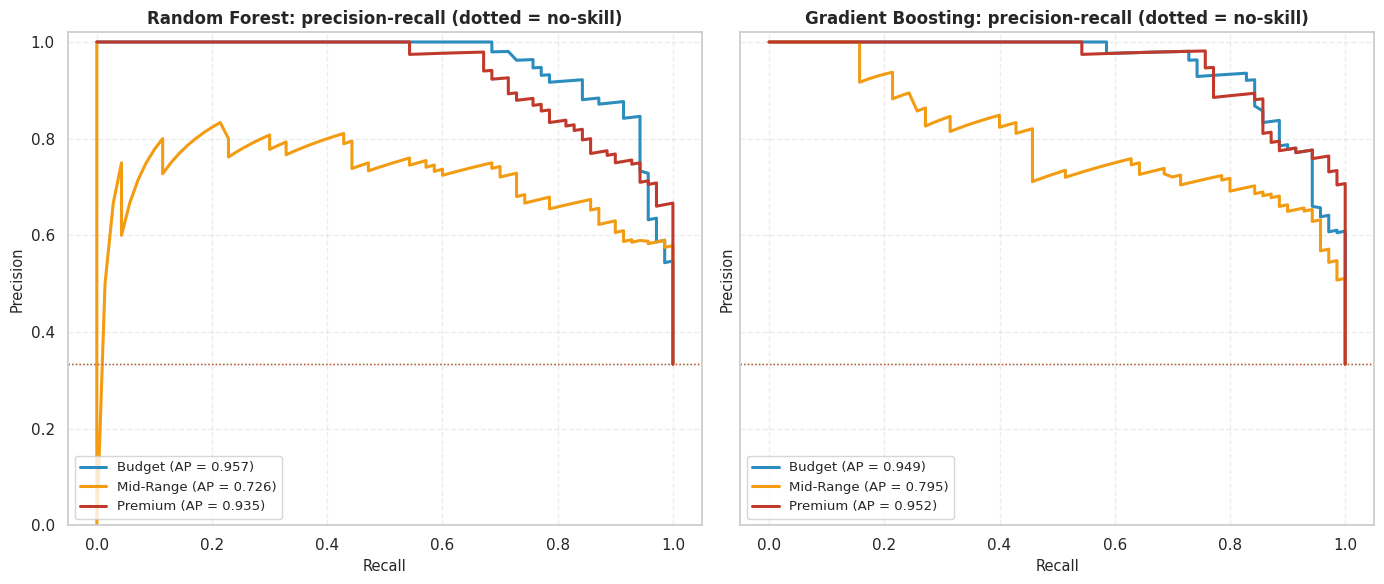

,Budget,Mid-Range,Premium,Mean_AP
Random Forest,0.957,0.726,0.935,0.873
Gradient Boosting,0.949,0.795,0.952,0.899


In [32]:
# FIGURE 14: Precision-Recall curves
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
ap_table = {}
for ax, name in zip(axes, best_models):
    ap_table[name] = {}
    for k, tier in enumerate(TIER_ORDER):
        p, r, _ = precision_recall_curve(y_test_bin[:, k], probas[name][:, k])
        ap = average_precision_score(y_test_bin[:, k], probas[name][:, k]); ap_table[name][tier] = round(ap, 3)
        ax.plot(r, p, color=TIER_COLORS[tier], lw=2.2, label=f"{tier} (AP = {ap:.3f})")
        ax.axhline(y_test_bin[:, k].mean(), color=TIER_COLORS[tier], ls=":", lw=1, alpha=0.7)
    ax.set_title(f"{name}: precision-recall (dotted = no-skill)", fontweight="bold"); ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.legend(loc="lower left")
    ax.set_ylim(0, 1.02)
save_show("fig14_precision_recall_curves.png")
display(pd.DataFrame(ap_table).T.assign(Mean_AP=lambda d: d.mean(axis=1).round(3)))

**Interpretation of Figure 14 (precision-recall curves).**

* Average precision: Random Forest 0.957 / 0.726 / 0.935 and Gradient Boosting 0.949 / 0.795 / 0.952 for Budget / Mid-Range / Premium. The dotted lines show the no-skill level (about 0.33 for each balanced class).
* **Mid-Range is again the weakest** (AP 0.73 to 0.80) but still more than twice the no-skill baseline.
* Gradient Boosting has the better Mid-Range average precision (0.795 vs 0.726), so its predicted probabilities rank Mid-Range phones better even though its hard Mid-Range recall is similar.

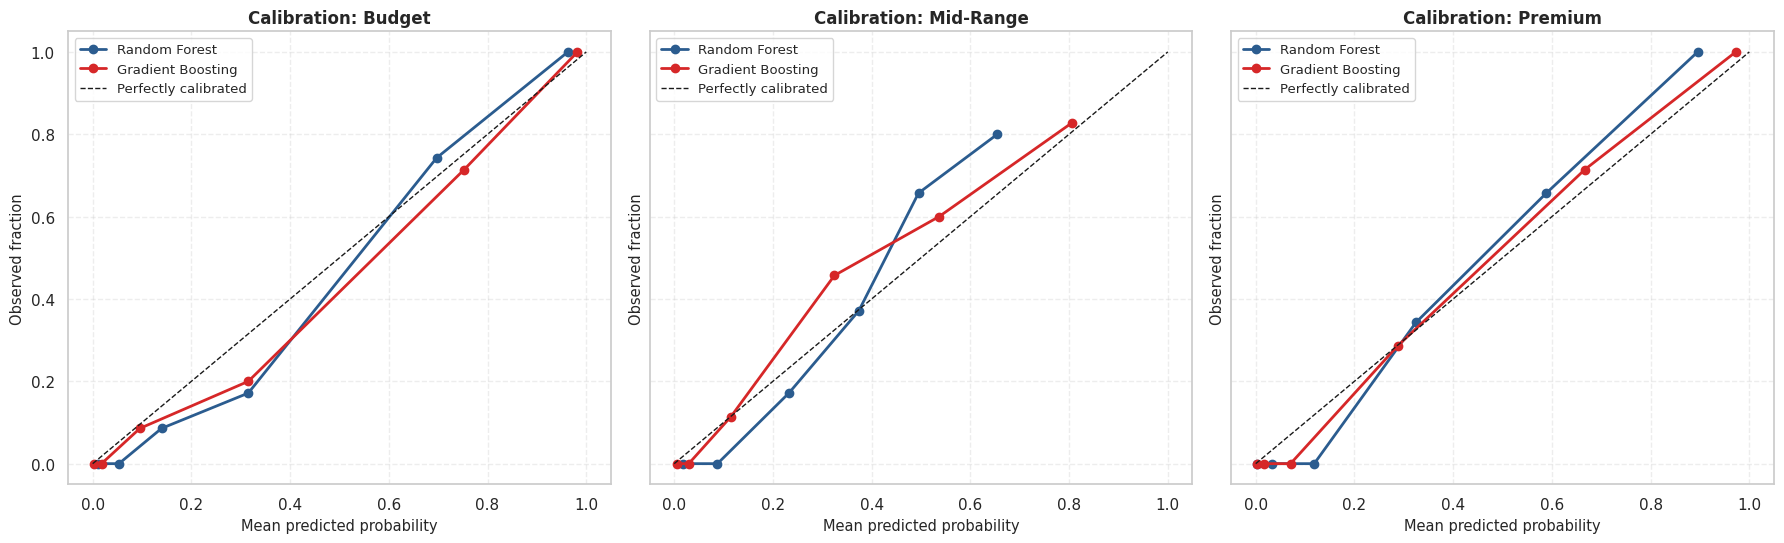

Mean Brier score (lower = better calibrated): {'Random Forest': np.float64(0.0936), 'Gradient Boosting': np.float64(0.0847)}


In [33]:
# FIGURE 15: Calibration of predicted probabilities (reliability diagrams, one-vs-rest)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6), sharey=True)
for k, (ax, tier) in enumerate(zip(axes, TIER_ORDER)):
    for name in best_models:
        frac_pos, mean_pred = calibration_curve(y_test_bin[:, k], probas[name][:, k], n_bins=6, strategy="quantile")
        ax.plot(mean_pred, frac_pos, "o-", color=MODEL_COLORS[name], lw=2, label=name)
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="Perfectly calibrated")
    ax.set_title(f"Calibration: {tier}", fontweight="bold"); ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed fraction")
    ax.legend(loc="upper left")
save_show("fig15_calibration_curves.png")

brier = {n: np.mean([np.mean((probas[n][:, k] - y_test_bin[:, k]) ** 2) for k in range(3)]) for n in best_models}
print("Mean Brier score (lower = better calibrated):", {k: round(v, 4) for k, v in brier.items()})

**Interpretation of Figure 15 (calibration).**

* A perfectly calibrated model follows the dashed diagonal: when it says 70%, the event happens 70% of the time.
* Mean Brier score is **0.0847 for Gradient Boosting vs 0.0936 for Random Forest** (lower is better), so Gradient Boosting's probabilities are somewhat better calibrated overall.
* Random Forest probabilities tend to be less extreme (averaging over many trees pulls probabilities toward the middle), which is a known characteristic of bagged ensembles. If the probabilities will be used directly, calibration (e.g. isotonic or Platt) would be a sensible next step.

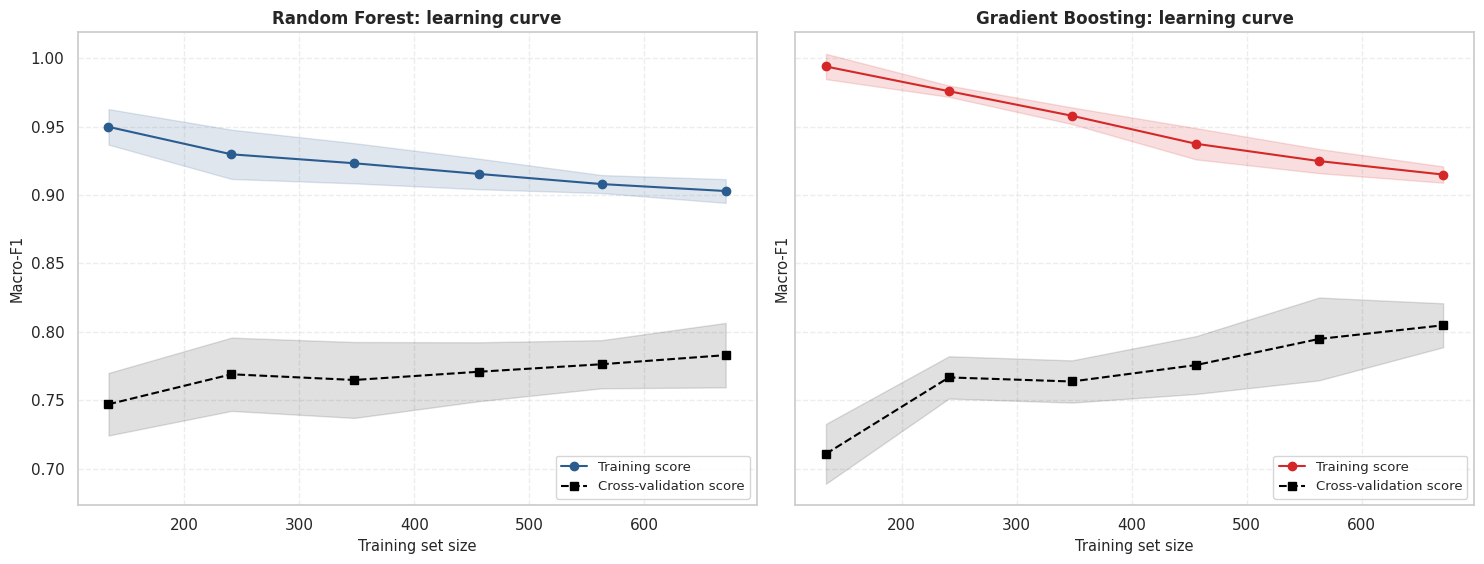

,train@max,cv@max,gap,cv gain last step
Model,,,,
Random Forest,0.9029,0.7831,0.1198,0.0066
Gradient Boosting,0.9149,0.8049,0.1100,0.0100


In [34]:
# FIGURE 16: Learning curves (does more data help? over-fitting vs under-fitting)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8), sharey=True)
lc_summary = []
for ax, (name, model) in zip(axes, best_models.items()):
    sizes, tr, va = learning_curve(model, X_train, y_train, cv=cv5, scoring="f1_macro",
                                   train_sizes=np.linspace(0.2, 1.0, 6), n_jobs=-1, random_state=RANDOM_SEED, shuffle=True)
    ax.plot(sizes, tr.mean(1), "o-", color=MODEL_COLORS[name], label="Training score"); ax.fill_between(sizes, tr.mean(1)-tr.std(1), tr.mean(1)+tr.std(1), alpha=0.15, color=MODEL_COLORS[name])
    ax.plot(sizes, va.mean(1), "s--", color="black", label="Cross-validation score"); ax.fill_between(sizes, va.mean(1)-va.std(1), va.mean(1)+va.std(1), alpha=0.12, color="black")
    ax.set_title(f"{name}: learning curve", fontweight="bold"); ax.set_xlabel("Training set size"); ax.set_ylabel("Macro-F1"); ax.legend(loc="lower right")
    lc_summary.append({"Model": name, "train@max": tr.mean(1)[-1], "cv@max": va.mean(1)[-1], "gap": tr.mean(1)[-1]-va.mean(1)[-1],
                       "cv gain last step": va.mean(1)[-1]-va.mean(1)[-2]})
save_show("fig16_learning_curves.png")
display(pd.DataFrame(lc_summary).set_index("Model").round(4))

**Interpretation of Figure 16 (learning curves).**

* There is a **train-validation gap of about 0.11 to 0.12 macro-F1** (training about 0.90 to 0.91 vs CV about 0.78 to 0.80). Both models fit the training data more tightly than they generalise, a moderate degree of over-fitting that is typical for tree ensembles.
* The CV curve is still **rising slowly** at full size (gain from the last step: +0.007 for RF, +0.010 for GB), so more data would help a little but not dramatically.
* The remaining error is probably dominated by information the specs do not contain (brand pricing strategy, launch timing, marketing) rather than by model capacity.

## Part I. Model Interpretation

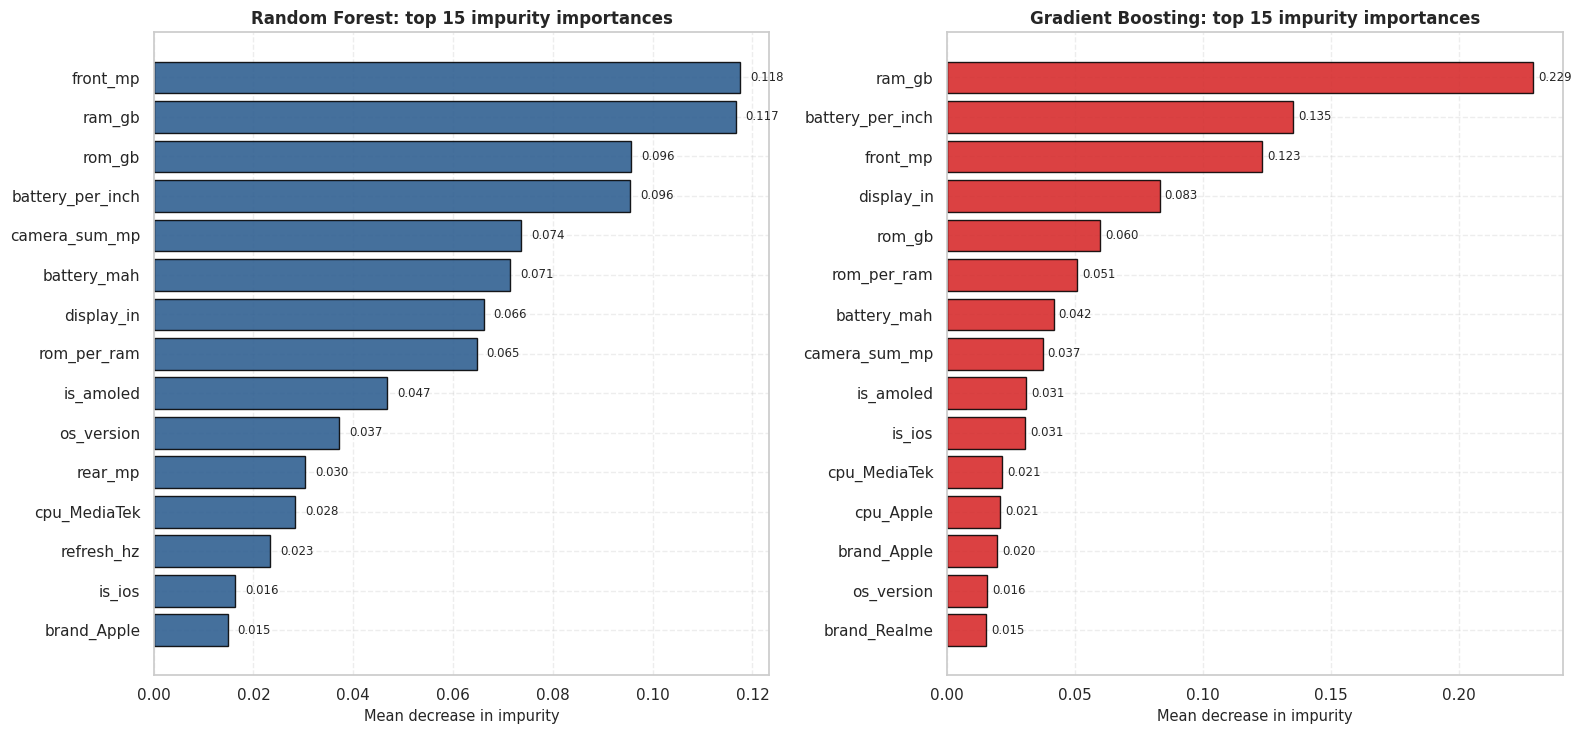

,Random Forest,Gradient Boosting
0,front_mp (0.1175),ram_gb (0.2292)
1,ram_gb (0.1167),battery_per_inch (0.1354)
2,rom_gb (0.0956),front_mp (0.1232)
3,battery_per_inch (0.0955),display_in (0.0832)
4,camera_sum_mp (0.0736),rom_gb (0.0599)
5,battery_mah (0.0715),rom_per_ram (0.0509)
6,display_in (0.0661),battery_mah (0.0418)
7,rom_per_ram (0.0647),camera_sum_mp (0.0374)
8,is_amoled (0.0468),is_amoled (0.0311)
9,os_version (0.0372),is_ios (0.0307)


In [35]:
# FIGURE 17: Built-in (impurity-based) feature importance, top 15
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))
imp_tables = {}
for ax, (name, model) in zip(axes, best_models.items()):
    imp = pd.Series(model.named_steps["clf"].feature_importances_, index=X.columns).sort_values(ascending=False)
    imp_tables[name] = imp
    top = imp.head(15)[::-1]
    ax.barh(top.index, top.values, color=MODEL_COLORS[name], edgecolor="black", alpha=0.88)
    for i, v in enumerate(top.values): ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8.5)
    ax.set_title(f"{name}: top 15 impurity importances", fontweight="bold"); ax.set_xlabel("Mean decrease in impurity")
save_show("fig17_feature_importance.png")
display(pd.DataFrame({n: imp.head(10).round(4).reset_index().apply(lambda r: f"{r.iloc[0]} ({r.iloc[1]})", axis=1) for n, imp in imp_tables.items()}))

**Interpretation of Figure 17 (impurity-based importance).**

* **Random Forest** spreads importance across `front_mp` (0.118), `ram_gb` (0.117), `rom_gb` (0.096) and `battery_per_inch` (0.096).
* **Gradient Boosting** concentrates on **`ram_gb` (0.229)**, then `battery_per_inch` (0.135) and `front_mp` (0.123).
* Both rank the engineered ratio `battery_per_inch` in the top 4, which confirms that feature engineering added signal.
* Caution: impurity importance favours features with many distinct values (like `front_mp`, `battery_mah`) and splits credit between correlated features. The permutation analysis below is a more reliable check.

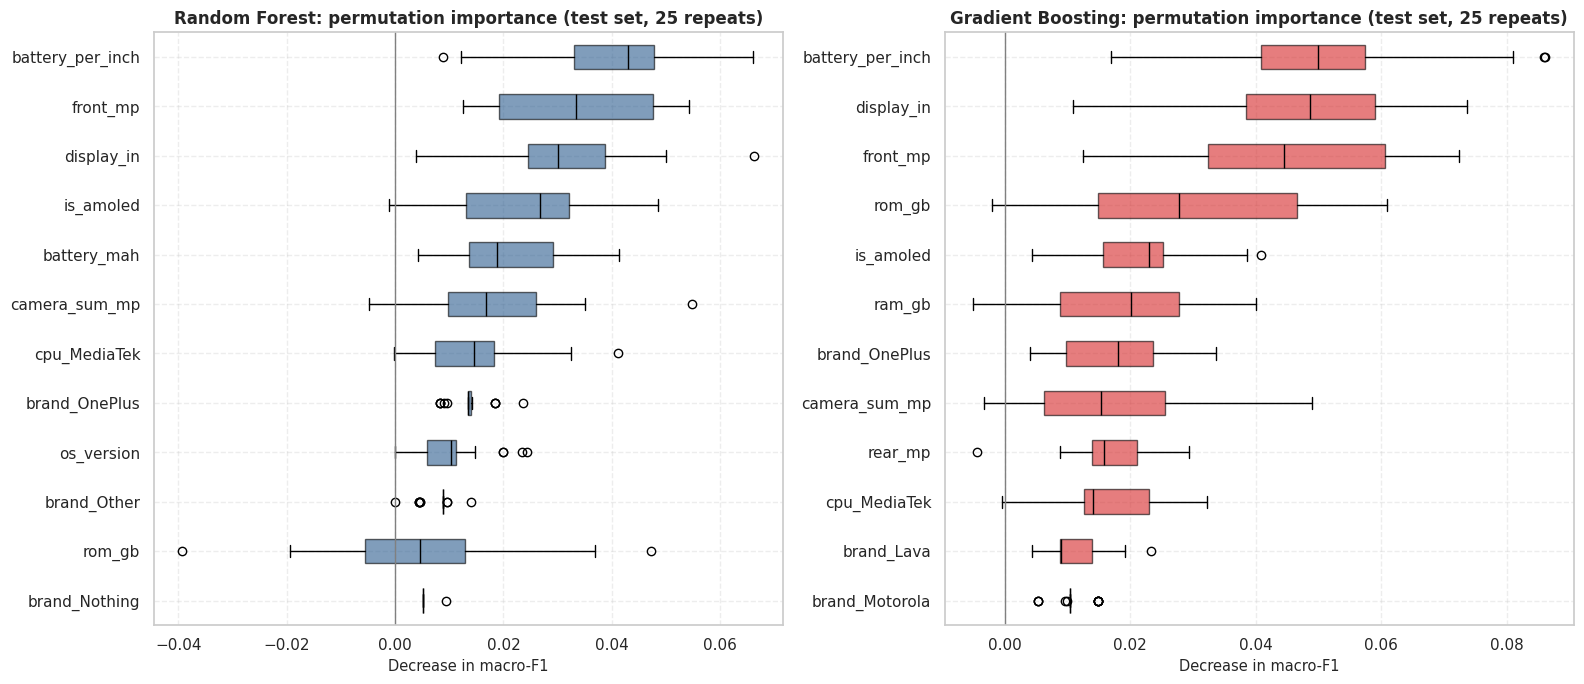

Permutation importance (mean drop in macro-F1) for the union of each model's top-8 features:


,Random Forest,Gradient Boosting
battery_per_inch,0.0403,0.0517
display_in,0.0323,0.0468
front_mp,0.0339,0.0434
is_amoled,0.0239,0.0216
rom_gb,0.0062,0.0295
camera_sum_mp,0.0176,0.0169
cpu_MediaTek,0.0149,0.0165
brand_OnePlus,0.0136,0.0175
battery_mah,0.0208,0.0009
ram_gb,0.0025,0.0184


In [36]:
# FIGURE 18: Permutation importance on the TEST set (drop in macro-F1 when a feature is shuffled)
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
perm_tables = {}
for ax, (name, model) in zip(axes, best_models.items()):
    pi = permutation_importance(model, X_test, y_test, scoring="f1_macro", n_repeats=25, random_state=RANDOM_SEED, n_jobs=-1)
    order = np.argsort(pi.importances_mean)[::-1][:12]
    perm_tables[name] = pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False)
    ax.boxplot(pi.importances[order][::-1].T, vert=False, labels=X.columns[order][::-1], patch_artist=True,
               boxprops=dict(facecolor=MODEL_COLORS[name], alpha=0.6), medianprops=dict(color="black"))
    ax.axvline(0, color="grey", lw=1); ax.set_title(f"{name}: permutation importance (test set, 25 repeats)", fontweight="bold")
    ax.set_xlabel("Decrease in macro-F1")
save_show("fig18_permutation_importance.png")
perm_all = pd.DataFrame(perm_tables)
keep = sorted(set(perm_all["Random Forest"].nlargest(8).index) | set(perm_all["Gradient Boosting"].nlargest(8).index),
              key=lambda f: -perm_all.loc[f].mean())
print("Permutation importance (mean drop in macro-F1) for the union of each model's top-8 features:")
display(perm_all.loc[keep].round(4))

**Interpretation of Figure 18 (permutation importance on the test set).**

* Shuffling a feature and measuring the macro-F1 drop shows what the trained models *actually rely on*. For both models the top features are **`battery_per_inch`** (RF -0.040, GB -0.052), **`display_in`**, **`front_mp`** and **`is_amoled`**, with `rom_gb` high for Gradient Boosting.
* `ram_gb` and `rom_gb` have large univariate effect sizes but modest permutation importance for Random Forest. This is **feature redundancy**: RAM, storage, `rom_per_ram` and brand/CPU indicators overlap, so shuffling one barely hurts because the others compensate. High univariate association does not mean high marginal contribution.
* Individual drops are small (a few percentage points), and the box plots show the spread across 25 shuffles: only the top few features are clearly above zero.

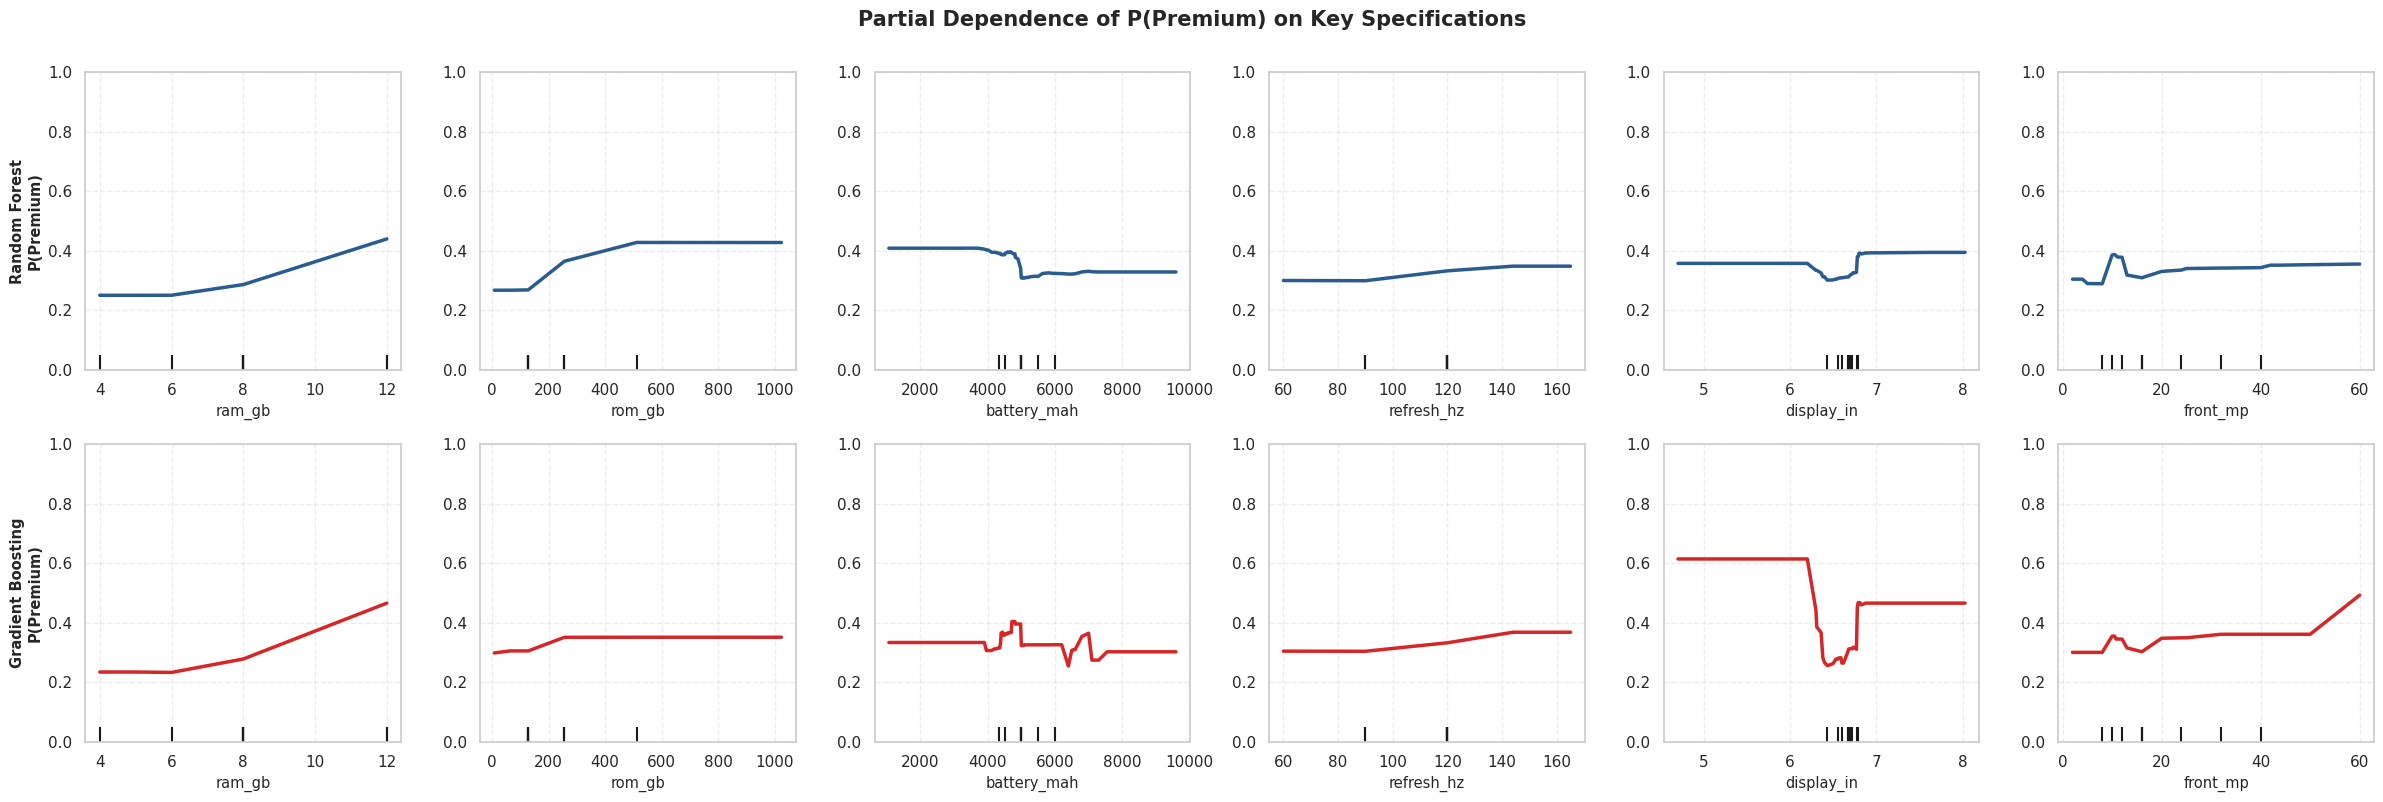

In [37]:
# FIGURE 19: Partial dependence for the Premium class (how each key spec moves P(Premium))
pd_feats = ["ram_gb", "rom_gb", "battery_mah", "refresh_hz", "display_in", "front_mp"]
fig, axes = plt.subplots(2, 6, figsize=(24, 8))
for row, (name, model) in enumerate(best_models.items()):
    PartialDependenceDisplay.from_estimator(model, X_train, pd_feats, target=2, kind="average", ax=axes[row],
                                            line_kw={"color": MODEL_COLORS[name], "lw": 2.5}, n_jobs=-1)
    for a in axes[row]: a.set_ylim(0, 1)
    axes[row][0].set_ylabel(f"{name}\nP(Premium)", fontweight="bold")
    for a in axes[row][1:]: a.set_ylabel("")
fig.suptitle("Partial Dependence of P(Premium) on Key Specifications", fontsize=15, fontweight="bold", y=1.0)
save_show("fig19_partial_dependence.png")

**Interpretation of Figure 19 (partial dependence for P(Premium)).**

* **RAM:** the probability of Premium rises with RAM in both models (roughly 0.25 at 4 to 6 GB to 0.45 at 12 GB). **Storage:** rises from 64 GB to 256 GB and then plateaus.
* **Refresh rate and front camera** have weak, nearly flat effects once the other features are averaged out.
* **Display size:** the sharp jump below about 6.3 inches reflects **iPhones** (small screens, all Premium), not a causal effect of screen size. Partial dependence plots average over the data and can reflect confounding with correlated features like `is_ios`.
* **Battery:** Random Forest shows a slightly lower Premium probability for larger batteries (matching the negative correlation seen earlier); Gradient Boosting's curve is noisier and nearly flat.

## Part J. Model Comparison and Statistical Testing

In [38]:
# Repeated stratified cross-validation (5 folds x 3 repeats = 15 scores per model)
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_SEED)
cv_scores = {n: cross_val_score(m, X, y, cv=rcv, scoring="f1_macro", n_jobs=-1) for n, m in best_models.items()}

rows = []
for n, s in cv_scores.items():
    ci = stats.t.interval(0.95, len(s) - 1, loc=s.mean(), scale=stats.sem(s))
    rows.append({"Model": n, "mean macro-F1": s.mean(), "std": s.std(), "min": s.min(), "max": s.max(), "95% CI low": ci[0], "95% CI high": ci[1]})
cv_table = pd.DataFrame(rows).set_index("Model").round(4)
display(cv_table)
print("Note: hyper-parameters were tuned on the training split, so these CV numbers use all data and are slightly optimistic;")
print("      the held-out test metrics above remain the unbiased headline numbers.")

,mean macro-F1,std,min,max,95% CI low,95% CI high
Model,,,,,,
Random Forest,0.7923,0.0249,0.7534,0.8397,0.7781,0.8066
Gradient Boosting,0.8061,0.0208,0.7635,0.8387,0.7942,0.8180


Note: hyper-parameters were tuned on the training split, so these CV numbers use all data and are slightly optimistic;
      the held-out test metrics above remain the unbiased headline numbers.


In [39]:
# Is the difference between the two models real? (paired Wilcoxon on CV folds + exact McNemar on the test set)
a, b = cv_scores["Random Forest"], cv_scores["Gradient Boosting"]
w_stat, w_p = stats.wilcoxon(a, b)
print(f"Paired Wilcoxon on 15 CV macro-F1 scores : W = {w_stat:.1f}, p = {w_p:.4f}   (mean diff RF - GB = {np.mean(a - b):+.4f})")

rf_ok = preds["Random Forest"] == y_test.values
gb_ok = preds["Gradient Boosting"] == y_test.values
b01 = int((rf_ok & ~gb_ok).sum()); c01 = int((~rf_ok & gb_ok).sum())
mc_p = stats.binomtest(b01, b01 + c01, 0.5).pvalue if (b01 + c01) > 0 else 1.0
print(f"Exact McNemar on {len(y_test)} test phones : RF-only correct = {b01}, GB-only correct = {c01}, p = {mc_p:.4f}")
print("Both correct:", int((rf_ok & gb_ok).sum()), "| both wrong:", int((~rf_ok & ~gb_ok).sum()))
print("\nReading the two tests together:")
print("  * Repeated-CV folds overlap in their training data, so their scores are correlated and the Wilcoxon p-value is optimistic.")
print("  * McNemar on the single untouched test set is the more conservative check.")
if w_p < 0.05 and mc_p < 0.05:
    print("  -> Both tests find a real difference between the models.")
elif w_p < 0.05 or mc_p < 0.05:
    print("  -> Mixed evidence: one test finds a small difference, the other does not. Treat the models as practically equivalent.")
else:
    print("  -> Neither test finds a difference: the models are statistically indistinguishable.")

Paired Wilcoxon on 15 CV macro-F1 scores : W = 14.0, p = 0.0067   (mean diff RF - GB = -0.0138)
Exact McNemar on 210 test phones : RF-only correct = 11, GB-only correct = 9, p = 0.8238
Both correct: 159 | both wrong: 31

Reading the two tests together:
  * Repeated-CV folds overlap in their training data, so their scores are correlated and the Wilcoxon p-value is optimistic.
  * McNemar on the single untouched test set is the more conservative check.
  -> Mixed evidence: one test finds a small difference, the other does not. Treat the models as practically equivalent.


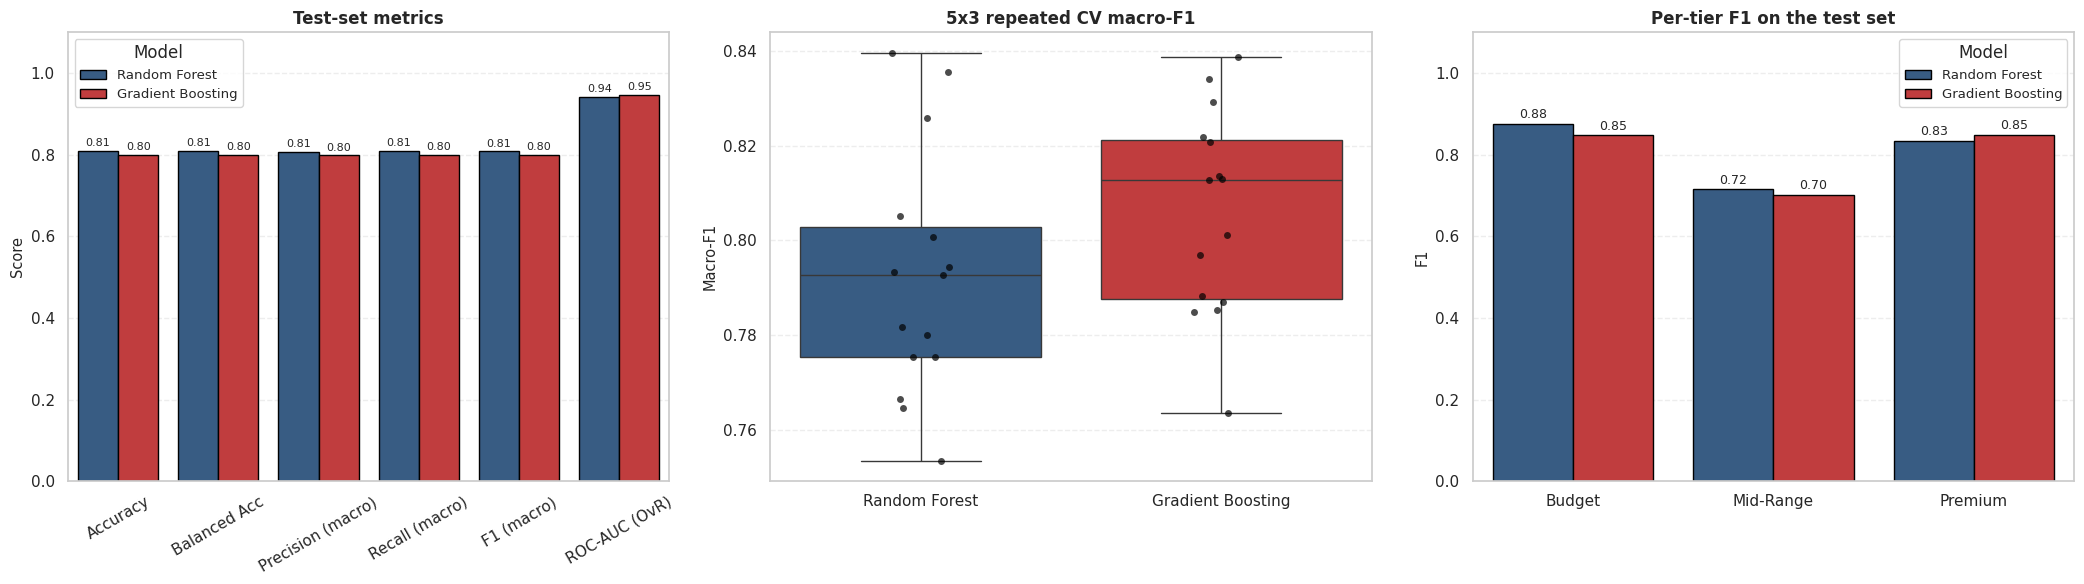

In [40]:
# FIGURE 20: Model comparison dashboard
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
long = df_results[["Accuracy", "Balanced Acc", "Precision (macro)", "Recall (macro)", "F1 (macro)", "ROC-AUC (OvR)"]].reset_index().melt(id_vars="Model", var_name="Metric", value_name="Score")
sns.barplot(data=long, x="Metric", y="Score", hue="Model", palette=MODEL_COLORS, edgecolor="black", ax=axes[0])
for c in axes[0].containers: axes[0].bar_label(c, fmt="%.2f", fontsize=8, padding=2)
axes[0].set_ylim(0, 1.1); axes[0].set_title("Test-set metrics", fontweight="bold"); axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=30)

cv_long = pd.DataFrame(cv_scores).melt(var_name="Model", value_name="Macro-F1")
sns.boxplot(data=cv_long, x="Model", y="Macro-F1", hue="Model", palette=MODEL_COLORS, legend=False, ax=axes[1])
sns.stripplot(data=cv_long, x="Model", y="Macro-F1", color="black", size=5, alpha=0.7, ax=axes[1])
axes[1].set_title("5x3 repeated CV macro-F1", fontweight="bold"); axes[1].set_xlabel("")

per_class = pd.DataFrame({n: f1_score(y_test, preds[n], average=None) for n in best_models}, index=TIER_ORDER).reset_index().melt(id_vars="index", var_name="Model", value_name="F1")
sns.barplot(data=per_class, x="index", y="F1", hue="Model", palette=MODEL_COLORS, edgecolor="black", ax=axes[2])
for c in axes[2].containers: axes[2].bar_label(c, fmt="%.2f", fontsize=9, padding=2)
axes[2].set_ylim(0, 1.1); axes[2].set_title("Per-tier F1 on the test set", fontweight="bold"); axes[2].set_xlabel("")
save_show("fig20_model_comparison.png")

**Interpretation of Figure 20 (model comparison dashboard).**

* **Test set (210 phones):** Random Forest leads on accuracy (0.810 vs 0.800), macro-F1 (0.808 vs 0.799) and MCC (0.715 vs 0.700); Gradient Boosting leads on ROC-AUC (0.947 vs 0.941) and Brier score.
* **Repeated CV (15 folds):** Gradient Boosting averages 0.806 macro-F1 (95% CI 0.794 to 0.818) vs 0.792 (0.778 to 0.807) for Random Forest, with the intervals overlapping.
* **Per tier:** Random Forest is slightly better on Budget and Mid-Range F1; Gradient Boosting on Premium. Mid-Range is the weakest tier for both.
* Overall, the differences are about **1 percentage point and point in different directions depending on the metric**, a sign the two models are essentially equivalent here.

## Part K. Error Analysis

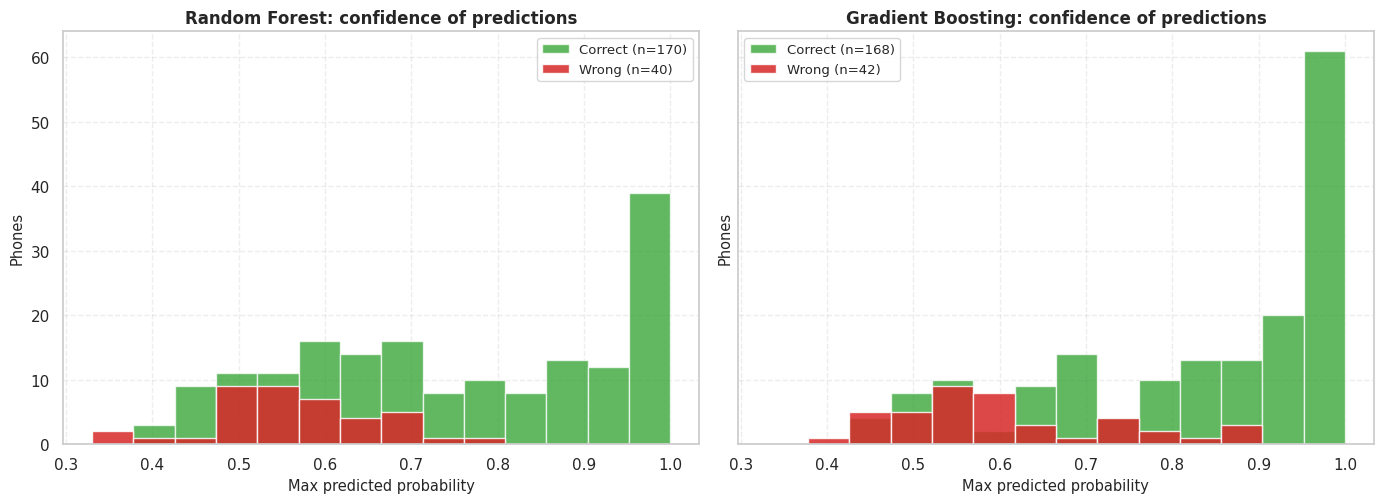

Mean confidence when correct vs wrong:


,correct,wrong
Random Forest,0.749,0.565
Gradient Boosting,0.831,0.605


In [41]:
# FIGURE 21: Prediction confidence, correct vs wrong (test set)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
for ax, name in zip(axes, best_models):
    conf = probas[name].max(axis=1); ok = preds[name] == y_test.values
    bins_c = np.linspace(0.33, 1, 15)
    ax.hist(conf[ok], bins=bins_c, alpha=0.75, color="#2ca02c", edgecolor="white", label=f"Correct (n={ok.sum()})")
    ax.hist(conf[~ok], bins=bins_c, alpha=0.85, color="#d62728", edgecolor="white", label=f"Wrong (n={(~ok).sum()})")
    ax.set_title(f"{name}: confidence of predictions", fontweight="bold"); ax.set_xlabel("Max predicted probability"); ax.set_ylabel("Phones"); ax.legend()
save_show("fig21_prediction_confidence.png")
print("Mean confidence when correct vs wrong:")
display(pd.DataFrame({n: {"correct": probas[n].max(1)[preds[n] == y_test.values].mean(),
                           "wrong": probas[n].max(1)[preds[n] != y_test.values].mean()} for n in best_models}).T.round(3))

**Interpretation of Figure 21 (prediction confidence).**

* Both models are **more confident when they are right**: mean top probability 0.749 (correct) vs 0.565 (wrong) for Random Forest, and 0.831 vs 0.605 for Gradient Boosting.
* Wrong predictions pile up at low confidence (0.4 to 0.6), so confidence is a **usable warning signal**: predictions below about 0.6 deserve a manual check or a 'borderline' label.
* Gradient Boosting is more confident overall, even when wrong, consistent with its sharper probabilities in the calibration analysis.

In [42]:
# Out-of-fold (OOF) predictions for ALL phones: every phone is predicted by a model that never saw it
oof_prob = {n: cross_val_predict(m, X, y, cv=cv5, method="predict_proba", n_jobs=-1) for n, m in best_models.items()}
oof_pred = {n: p.argmax(1) for n, p in oof_prob.items()}

oof_summary = pd.DataFrame({n: {"OOF accuracy": accuracy_score(y, oof_pred[n]), "OOF macro-F1": f1_score(y, oof_pred[n], average="macro"),
                                "OOF ROC-AUC": roc_auc_score(y, oof_prob[n], multi_class="ovr"),
                                "off-by-1 tier errors": int((np.abs(oof_pred[n] - y.values) == 1).sum()),
                                "off-by-2 tier errors": int((np.abs(oof_pred[n] - y.values) == 2).sum())} for n in best_models}).T
display(oof_summary.round(4))

,OOF accuracy,OOF macro-F1,OOF ROC-AUC,off-by-1 tier errors,off-by-2 tier errors
Random Forest,0.7931,0.7950,0.9308,213.0,4.0
Gradient Boosting,0.7979,0.7988,0.9351,209.0,3.0


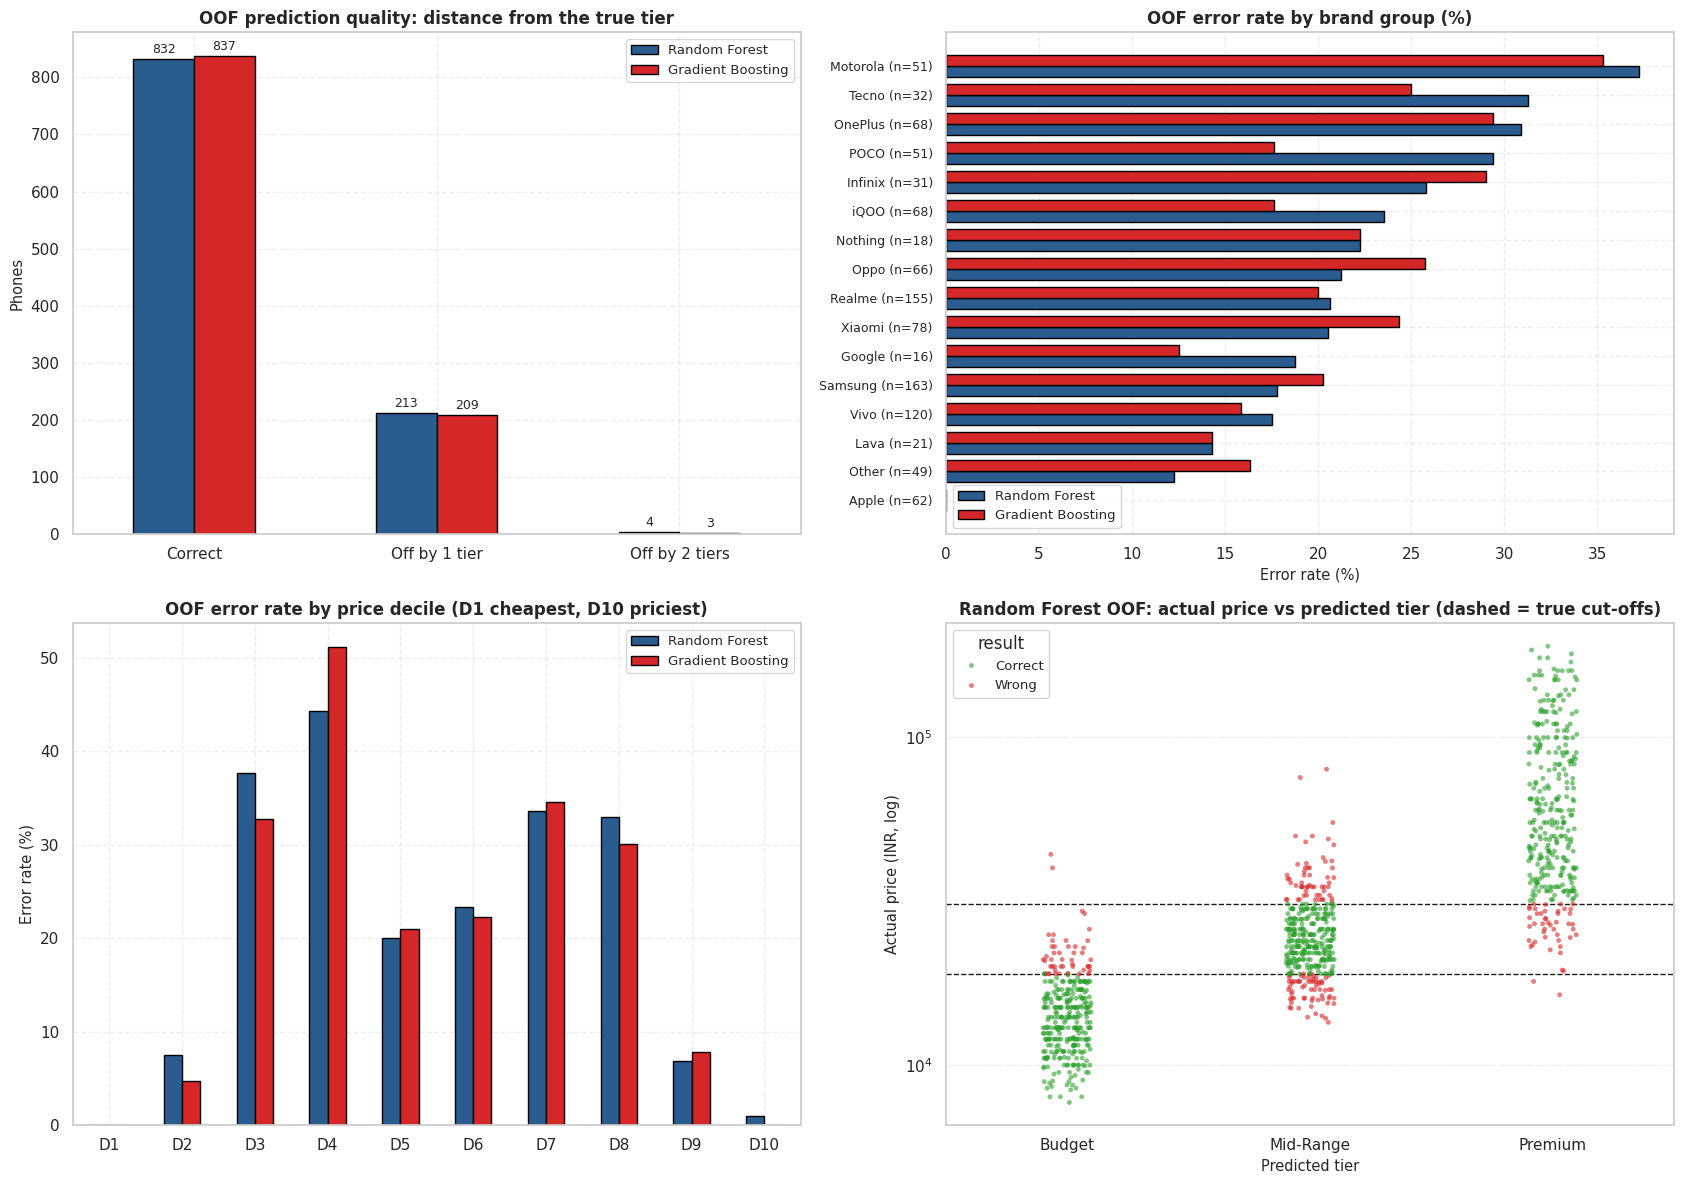

In [43]:
# FIGURE 22: Where do the errors happen? By tier distance, brand and price band
fig, axes = plt.subplots(2, 2, figsize=(17, 12))

dist = pd.DataFrame({n: pd.Series(np.abs(oof_pred[n] - y.values)).value_counts().reindex([0, 1, 2], fill_value=0) for n in best_models})
dist.index = ["Correct", "Off by 1 tier", "Off by 2 tiers"]
dist.plot(kind="bar", color=[MODEL_COLORS[n] for n in dist.columns], edgecolor="black", ax=axes[0, 0], rot=0)
for c in axes[0, 0].containers: axes[0, 0].bar_label(c, fontsize=9, padding=2)
axes[0, 0].set_title("OOF prediction quality: distance from the true tier", fontweight="bold"); axes[0, 0].set_ylabel("Phones")

err = pd.DataFrame({"brand": df["brand_group"].values})
for n in best_models: err[n] = (oof_pred[n] != y.values).astype(int)
by_brand = err.groupby("brand").agg(n=("brand", "size"), **{n: (n, "mean") for n in best_models}).sort_values("Random Forest")
yb = np.arange(len(by_brand)); h = 0.38
axes[0, 1].barh(yb - h/2, by_brand["Random Forest"] * 100, h, color=MODEL_COLORS["Random Forest"], edgecolor="black", label="Random Forest")
axes[0, 1].barh(yb + h/2, by_brand["Gradient Boosting"] * 100, h, color=MODEL_COLORS["Gradient Boosting"], edgecolor="black", label="Gradient Boosting")
axes[0, 1].set_yticks(yb); axes[0, 1].set_yticklabels([f"{b} (n={n})" for b, n in zip(by_brand.index, by_brand["n"])], fontsize=9)
axes[0, 1].set_title("OOF error rate by brand group (%)", fontweight="bold"); axes[0, 1].set_xlabel("Error rate (%)"); axes[0, 1].legend()

band = pd.qcut(df["price_inr"], 10, labels=[f"D{i}" for i in range(1, 11)])
by_band = pd.DataFrame({n: pd.Series((oof_pred[n] != y.values).astype(int)).groupby(band.values).mean() * 100 for n in best_models})
by_band.plot(kind="bar", color=[MODEL_COLORS[n] for n in by_band.columns], edgecolor="black", ax=axes[1, 0], rot=0)
axes[1, 0].set_title("OOF error rate by price decile (D1 cheapest, D10 priciest)", fontweight="bold"); axes[1, 0].set_ylabel("Error rate (%)"); axes[1, 0].set_xlabel("")

pt = pd.DataFrame({"pred": [TIER_ORDER[i] for i in oof_pred["Random Forest"]], "price": df["price_inr"].values,
                   "result": np.where(oof_pred["Random Forest"] == y.values, "Correct", "Wrong")})
sns.stripplot(data=pt, x="pred", y="price", hue="result", order=TIER_ORDER, palette={"Correct": "#2ca02c", "Wrong": "#d62728"}, size=3.5, alpha=0.6, ax=axes[1, 1])
axes[1, 1].set_yscale("log"); axes[1, 1].axhline(q1, color="k", ls="--", lw=1); axes[1, 1].axhline(q2, color="k", ls="--", lw=1)
axes[1, 1].set_title("Random Forest OOF: actual price vs predicted tier (dashed = true cut-offs)", fontweight="bold")
axes[1, 1].set_xlabel("Predicted tier"); axes[1, 1].set_ylabel("Actual price (INR, log)")
save_show("fig22_error_analysis.png")

**Interpretation of Figure 22 (out-of-fold error analysis, all 1,049 phones).**

* **Errors are near-misses.** Of the roughly 215 mistakes per model, 213 (RF) and 209 (GB) are off by exactly one tier; only 4 and 3 are off by two.
* **By price:** error rates spike in deciles D3-D4 and D7-D8, exactly the phones that sit **on the tier boundaries** (about 33rd and 67th percentiles), while the cheapest (D1) and most expensive (D10) deciles are almost error-free.
* **By brand:** Apple has no errors (all Premium). The hardest brands are **Motorola (35 to 37% errors)**, **OnePlus (29 to 31%)**, **Tecno (25 to 31%)** and **Infinix (26 to 29%)**, all brands that price across tier boundaries. POCO is hard for Random Forest (29%) but easier for Gradient Boosting (18%).
* **Bottom-right:** the red (wrong) points cluster just across the dashed cut-offs; the models rarely place a phone far from its true price band.

In [44]:
# Concrete mistakes: test-set phones that BOTH models got wrong (most informative failures)
info = df.loc[X_test.index, ["brand", "processor", "ram_gb", "rom_gb", "battery_mah", "refresh_hz", "price_inr", "price_tier"]].copy()
info["RF"] = pd.Series(preds["Random Forest"], index=X_test.index).map(dict(enumerate(TIER_ORDER)))
info["GB"] = pd.Series(preds["Gradient Boosting"], index=X_test.index).map(dict(enumerate(TIER_ORDER)))
both_wrong = info[(info["RF"] != info["price_tier"]) & (info["GB"] != info["price_tier"])]
print(f"Phones both models misclassify: {len(both_wrong)} of {len(info)} test phones")
display(both_wrong.sort_values("price_inr").head(12))

Phones both models misclassify: 31 of 210 test phones


,brand,processor,ram_gb,rom_gb,battery_mah,refresh_hz,price_inr,price_tier,RF,GB
248,POCO,MediaTek,8.0,256.0,5110,120,14899,Budget,Mid-Range,Mid-Range
1033,Infinix,MediaTek,8.0,256.0,5000,120,15999,Budget,Mid-Range,Mid-Range
458,Tecno,MediaTek,8.0,256.0,6000,144,15999,Budget,Mid-Range,Premium
455,Realme,MediaTek,8.0,256.0,5000,120,16899,Budget,Mid-Range,Mid-Range
780,Oppo,MediaTek,8.0,128.0,4310,60,16990,Budget,Mid-Range,Mid-Range
754,OnePlus,MediaTek,6.0,128.0,4500,90,18990,Budget,Mid-Range,Mid-Range
420,Vivo,Snapdragon,8.0,256.0,6500,120,18999,Mid-Range,Budget,Budget
816,Tecno,MediaTek,12.0,256.0,6000,120,19380,Mid-Range,Premium,Premium
842,Realme,MediaTek,6.0,128.0,5000,90,19490,Mid-Range,Budget,Budget
923,Xiaomi,Snapdragon,8.0,128.0,4820,120,19840,Mid-Range,Budget,Budget


## Part L. Robustness: Sensitivity to the RAM Repair

In [45]:
# The RAM repair (values 1 and 2 -> 12 GB) was an assumption. How much does it matter?
variants = {"A. Raw RAM as stored (1 and 2 kept)": df["Ram_GB"].astype(float),
            "B. Recoded to 12 GB (used in this notebook)": df["ram_gb"],
            "C. Treated as missing (median-imputed)": df["Ram_GB"].where(~df["Ram_GB"].isin([1, 2]), np.nan).astype(float)}
rf_fixed = RandomForestClassifier(**{k.replace("clf__", ""): v for k, v in best_params["Random Forest"].items()}, random_state=RANDOM_SEED, n_jobs=-1)
rows = []
for label, ram in variants.items():
    Xv = build_feature_matrix(df, ram)
    pipe = make_pipe(rf_fixed)
    s = cross_val_score(pipe, Xv.loc[X_train.index], y_train, cv=cv5, scoring="f1_macro")
    pipe.fit(Xv.loc[X_train.index], y_train); yp = pipe.predict(Xv.loc[X_test.index])
    rows.append({"RAM treatment": label, "CV macro-F1 (train)": s.mean(), "Test accuracy": accuracy_score(y_test, yp), "Test macro-F1": f1_score(y_test, yp, average="macro")})
sens = pd.DataFrame(rows).set_index("RAM treatment").round(4)
display(sens)

,CV macro-F1 (train),Test accuracy,Test macro-F1
RAM treatment,,,
A. Raw RAM as stored (1 and 2 kept),0.7667,0.8000,0.7978
B. Recoded to 12 GB (used in this notebook),0.7889,0.8095,0.8083
C. Treated as missing (median-imputed),0.7823,0.8381,0.8388


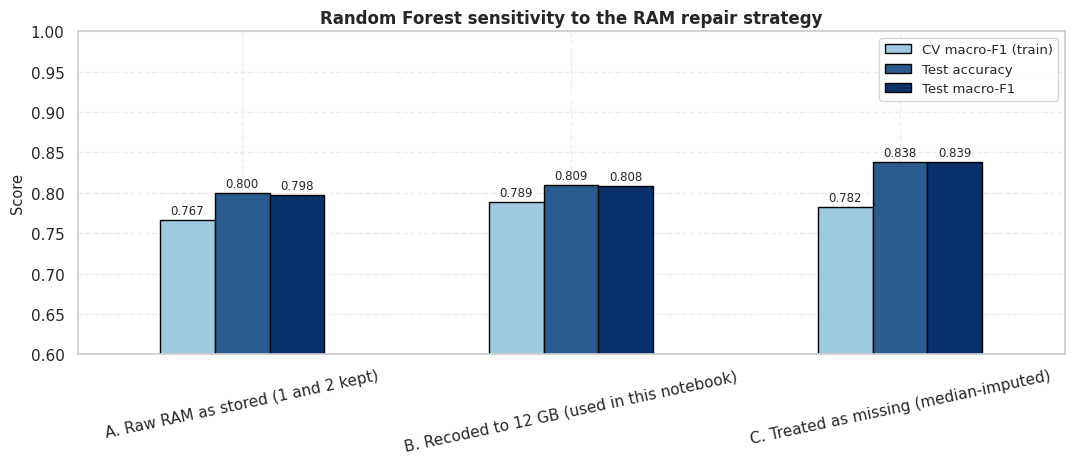

In [46]:
# FIGURE 23: Sensitivity result
fig, ax = plt.subplots(figsize=(11, 4.8))
sens[["CV macro-F1 (train)", "Test accuracy", "Test macro-F1"]].plot(kind="bar", ax=ax, edgecolor="black", rot=12, color=["#9ecae1", "#2b5c8f", "#08306b"])
for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=8.5, padding=2)
ax.set_ylim(0.6, 1.0); ax.set_ylabel("Score"); ax.set_xlabel(""); ax.set_title("Random Forest sensitivity to the RAM repair strategy", fontweight="bold")
save_show("fig23_ram_sensitivity.png")

**Interpretation of Figure 23 (RAM-repair sensitivity).**

* Leaving the corrupt RAM values as stored (variant A) gives the **lowest** CV macro-F1 (0.767 vs 0.789 for the recode and 0.782 for treating them as missing).
* On the 210-phone test set, variant C scores highest (macro-F1 0.839) and B 0.808. With only 210 test phones, one standard error is roughly 2.7 percentage points, so **B and C cannot be told apart**; only the cleaner treatments clearly beat leaving the errors in.
* Conclusion: repairing the RAM encoding matters (about 2 points of CV macro-F1), but the exact repair choice (12 GB vs missing) does not change the story. The headline results are robust to this assumption.

## Part M. Using the Trained Models and Saving Everything

In [47]:
# Predict the tier of a NEW hypothetical phone with both models
def predict_phone(spec, brand="Samsung", processor="Snapdragon"):
    row = pd.DataFrame(0.0, index=[0], columns=X.columns)
    for k, v in spec.items(): row.loc[0, k] = v
    row.loc[0, "camera_sum_mp"] = spec["rear_mp"] + spec["front_mp"]
    row.loc[0, "battery_per_inch"] = spec["battery_mah"] / spec["display_in"]
    row.loc[0, "rom_per_ram"] = spec["rom_gb"] / spec["ram_gb"]
    for col in (f"brand_{brand}", f"cpu_{processor}"):
        if col in row.columns: row.loc[0, col] = 1.0
    return pd.DataFrame({n: m.predict_proba(row)[0] for n, m in best_models.items()}, index=TIER_ORDER).T.round(3)

examples = {
    "Entry phone  (4 GB / 64 GB, LCD, 5000 mAh, 60 Hz)": (dict(ram_gb=4, rom_gb=64, battery_mah=5000, display_in=6.5, refresh_hz=60, rear_mp=13, front_mp=5, os_version=13, is_ios=0, is_amoled=0), "Infinix", "MediaTek"),
    "Mid phone    (8 GB / 128 GB, AMOLED, 5500 mAh, 120 Hz)": (dict(ram_gb=8, rom_gb=128, battery_mah=5500, display_in=6.7, refresh_hz=120, rear_mp=50, front_mp=16, os_version=14, is_ios=0, is_amoled=1), "Realme", "MediaTek"),
    "Flagship     (12 GB / 512 GB, AMOLED, 144 Hz)": (dict(ram_gb=12, rom_gb=512, battery_mah=5000, display_in=6.8, refresh_hz=144, rear_mp=200, front_mp=12, os_version=15, is_ios=0, is_amoled=1), "Samsung", "Snapdragon"),
}
for title, (spec, b, p) in examples.items():
    print(f"\n{title}  [{b}, {p}] -> predicted tier probabilities")
    display(predict_phone(spec, b, p))


Entry phone  (4 GB / 64 GB, LCD, 5000 mAh, 60 Hz)  [Infinix, MediaTek] -> predicted tier probabilities


,Budget,Mid-Range,Premium
Random Forest,0.925,0.068,0.007
Gradient Boosting,0.997,0.002,0.001



Mid phone    (8 GB / 128 GB, AMOLED, 5500 mAh, 120 Hz)  [Realme, MediaTek] -> predicted tier probabilities


,Budget,Mid-Range,Premium
Random Forest,0.400,0.555,0.045
Gradient Boosting,0.127,0.868,0.006



Flagship     (12 GB / 512 GB, AMOLED, 144 Hz)  [Samsung, Snapdragon] -> predicted tier probabilities


,Budget,Mid-Range,Premium
Random Forest,0.031,0.096,0.873
Gradient Boosting,0.019,0.035,0.945


In [48]:
import joblib
# Save data, tables, importances and trained models
df.drop(columns=["os"], errors="ignore").to_csv(OUT_DIR / "mobiles_clean_dataset.csv", index=False)
X.to_csv(OUT_DIR / "feature_matrix.csv", index=False)
df_results.to_csv(OUT_DIR / "model_results.csv")
cv_table.to_csv(OUT_DIR / "cv_summary.csv")
sens.to_csv(OUT_DIR / "ram_sensitivity.csv")
kw.to_csv(OUT_DIR / "kruskal_wallis_tests.csv"); chi_tbl.to_csv(OUT_DIR / "chi_square_tests.csv")
pd.DataFrame(imp_tables).to_csv(OUT_DIR / "feature_importance_impurity.csv")
pd.DataFrame(perm_tables).to_csv(OUT_DIR / "feature_importance_permutation.csv")
joblib.dump({"models": best_models, "features": list(X.columns), "tiers": TIER_ORDER, "thresholds_inr": (float(q1), float(q2))},
            OUT_DIR / "price_tier_models.joblib")

print("Saved files:")
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file(): print(f"  {str(p.relative_to(OUT_DIR)):<48}{p.stat().st_size/1024:9.1f} KB")
print(f"\nFigures generated: {FIG_COUNTER['n']}")

Saved files:
  chi_square_tests.csv                                  0.2 KB
  cv_summary.csv                                        0.2 KB
  feature_importance_impurity.csv                       1.8 KB
  feature_importance_permutation.csv                    1.8 KB
  feature_matrix.csv                                  172.6 KB
  figures/fig01_data_quality_overview.png             441.3 KB
  figures/fig02_price_distribution.png                303.9 KB
  figures/fig03_brand_positioning.png                 389.1 KB
  figures/fig04_feature_distributions.png             677.8 KB
  figures/fig05_categorical_vs_tier.png               296.7 KB
  figures/fig06_specs_by_tier_boxplots.png            311.6 KB
  figures/fig07_correlation_heatmap.png               467.2 KB
  figures/fig08_pairplot.png                          501.5 KB
  figures/fig09_pca_projection.png                    556.6 KB
  figures/fig10_effect_sizes.png                      274.0 KB
  figures/fig11_hyperparameter_heatmaps.pn

## Part N. Final Summary

In [49]:
best_name = df_results["F1 (macro)"].idxmax()
print("=" * 82)
print("FINAL SUMMARY")
print("=" * 82)
print(f"Dataset        : {len(df_raw):,} raw rows -> {len(df):,} clean phones, {X.shape[1]} features ({df['brand'].nunique()} brands)")
print(f"Target         : 3 price tiers (cut-offs Rs {q1:,.0f} / Rs {q2:,.0f}), ~equal class sizes")
print(f"Models         : Random Forest, Gradient Boosting (Pipeline: median imputer + classifier)")
print(f"Test set       : {len(X_test)} phones")
print("-" * 82)
print(df_results[["Accuracy", "F1 (macro)", "ROC-AUC (OvR)", "MCC", "Quad. Kappa"]].to_string())
print("-" * 82)
print(f"Higher test macro-F1 : {best_name}")
print(f"Top permutation features (RF) : {', '.join(perm_tables['Random Forest'].head(4).index)}")
print(f"Top permutation features (GB) : {', '.join(perm_tables['Gradient Boosting'].head(4).index)}")
print(f"Model difference tests : Wilcoxon on CV folds p = {w_p:.3f} | McNemar on test set p = {mc_p:.3f}")
print("=" * 82)

try:                                        # in Colab: download everything as one zip
    import shutil
    from google.colab import files
    shutil.make_archive("/content/mobile_ml_outputs", "zip", OUT_DIR)
    files.download("/content/mobile_ml_outputs.zip")
except ImportError:
    pass

FINAL SUMMARY
Dataset        : 1,056 raw rows -> 1,049 clean phones, 34 features (27 brands)
Target         : 3 price tiers (cut-offs Rs 18,990 / Rs 30,999), ~equal class sizes
Models         : Random Forest, Gradient Boosting (Pipeline: median imputer + classifier)
Test set       : 210 phones
----------------------------------------------------------------------------------
                   Accuracy  F1 (macro)  ROC-AUC (OvR)     MCC  Quad. Kappa
Model                                                                      
Random Forest        0.8095      0.8083         0.9411  0.7146       0.8481
Gradient Boosting    0.8000      0.7990         0.9471  0.7003       0.8410
----------------------------------------------------------------------------------
Higher test macro-F1 : Random Forest
Top permutation features (RF) : battery_per_inch, front_mp, display_in, is_amoled
Top permutation features (GB) : battery_per_inch, display_in, front_mp, rom_gb
Model difference tests : Wilcoxon on 

---
## Conclusions

**RQ1: Can specs discriminate the tiers?** Yes. Both models reach about **80% accuracy** on three balanced classes (chance = 33%), with macro ROC-AUC of 0.94 to 0.95 and quadratic-weighted kappa of 0.84 to 0.85. Nearly all errors are adjacent-tier near-misses (Budget-to-Premium confusions are almost absent).

**RQ2: Which specs matter?** RAM and storage have the strongest univariate relationship with price. Inside the trained models the most relied-upon features are the engineered `battery_per_inch`, `front_mp`, `display_in`, `is_amoled` and RAM/storage. Processor family (Apple, Google, MediaTek) and the iOS flag are decisive for the brands they identify.

**RQ3: Random Forest vs Gradient Boosting?** Practically equivalent. Random Forest is marginally better on test accuracy and macro-F1 (+0.9 points), Gradient Boosting on ROC-AUC, Brier score and repeated-CV macro-F1 (+1.4 points). The test-set McNemar test (p = 0.82) finds no significant difference, and the CV-fold Wilcoxon p-value is optimistic because folds overlap.

**RQ4: Where do they fail?** On the **Mid-Range** tier (F1 about 0.70 to 0.72) and for phones priced within a few thousand rupees of a tier cut-off. Brands that price across all tiers (Motorola, OnePlus, Tecno, POCO, Infinix) are hardest.

### Limitations
* **Relative tiers:** tertile cut-offs (Rs 18,990 and Rs 30,999) depend on this dataset and on launch-price inflation over time. The data has no launch date.
* **Data repair assumption:** RAM values 1 and 2 were recoded as 12 GB. The sensitivity test shows robustness, but the true values are unknown.
* **Near-duplicate phones:** variants of the same model (different storage or colour) can fall in both train and test, which may flatter the scores slightly. Only exact duplicates were removed.
* **Missing price drivers:** brand strategy, chipset generation, camera quality and build materials are not in the data, which bounds achievable accuracy.
* **Small test set:** 210 phones means roughly +/- 3 points of sampling noise on any accuracy figure.

### Possible extensions
Ordinal or regression models for exact price, probability calibration, SHAP explanations (needs the `shap` package), more engineered features (chip generation, release year), and grouped splits by phone model to remove near-duplicate leakage.